In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving online+retail.zip to online+retail.zip


In [3]:
import zipfile
import os

with zipfile.ZipFile("online+retail.zip", "r") as zip_ref:
    zip_ref.extractall("retail_dataset")

print("Dataset extracted successfully!")
print("Files:", os.listdir("retail_dataset"))

Dataset extracted successfully!
Files: ['Online Retail.xlsx']


In [4]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("retail_dataset")
DATA_FILE = DATA_DIR / "Online Retail.xlsx"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

df = pd.read_excel(DATA_FILE)

print(f"Dataset loaded successfully: {DATA_FILE.name}")
print(f"Records: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully: Online Retail.xlsx
Records: 541,909
Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("DATASET DIMENSIONS")
print(df.shape)

print("\nDATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

DATASET DIMENSIONS
(541909, 8)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

MISSING VALUES
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

DUPLICATE RECORDS
5268


In [6]:
# 1. INVESTIGATE MISSING CUSTOMER IDs
# Identify transactions where the customer could not be identified.
print("MISSING CUSTOMER IDs")
display(df[df["CustomerID"].isna()].head(10))


# 2. INVESTIGATE MISSING PRODUCT DESCRIPTIONS
# Display records where the product description is unavailable.
print("\nMISSING PRODUCT DESCRIPTIONS")
display(df[df["Description"].isna()].head(10))


# 3. IDENTIFY CANCELLED INVOICES
# In this dataset, cancelled invoice numbers generally begin with "C".
# Count the transaction records associated with these invoices.
print("\nCANCELLED INVOICES")
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled invoice records:", cancelled.sum())


# 4. INVESTIGATE PRODUCT QUANTITIES
# Identify records with zero or negative quantities.
# Negative quantities may represent returned or reversed transactions.
print("\nQUANTITY INVESTIGATION")
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())


# 5. INVESTIGATE UNIT PRICES
# Identify products recorded with zero or negative unit prices.
print("\nUNIT PRICE INVESTIGATION")
print("Zero prices:", (df["UnitPrice"] == 0).sum())
print("Negative prices:", (df["UnitPrice"] < 0).sum())


# 6. CHECK DUPLICATE RECORDS
# Count rows where every column matches another existing record.
print("\nDUPLICATE RECORDS")
print("Duplicate rows:", df.duplicated().sum())

MISSING CUSTOMER IDs


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom



MISSING PRODUCT DESCRIPTIONS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



CANCELLED INVOICES
Cancelled invoice records: 9288

QUANTITY INVESTIGATION
Zero quantities: 0
Negative quantities: 10624

UNIT PRICE INVESTIGATION
Zero prices: 2515
Negative prices: 2

DUPLICATE RECORDS
Duplicate rows: 5268


In [7]:
# 1. COMPARE CANCELLED INVOICES WITH NEGATIVE QUANTITIES
# Create a condition identifying transactions with negative quantities.
negative_quantity = df["Quantity"] < 0

# Count records that satisfy both conditions.
# This helps us understand how cancellations and returns overlap.
print("CANCELLED INVOICES WITH NEGATIVE QUANTITIES:")
print((cancelled & negative_quantity).sum())

# Count negative-quantity records that do not have cancelled invoice numbers.
print("\nNEGATIVE QUANTITIES WITHOUT CANCELLED INVOICE NUMBERS:")
print((~cancelled & negative_quantity).sum())


# 2. EXAMINE NEGATIVE-PRICE TRANSACTIONS
# Display all records with negative unit prices for closer inspection.
print("\nNEGATIVE-PRICE TRANSACTIONS:")
display(df[df["UnitPrice"] < 0])


# 3. EXAMINE ZERO-PRICE TRANSACTIONS
# Display a sample of records where the unit price is zero.
# These may represent free items or unusual transaction entries.
print("\nSAMPLE ZERO-PRICE TRANSACTIONS:")
display(df[df["UnitPrice"] == 0].head(10))


# 4. EXAMINE CANCELLED INVOICES
# Display sample cancelled transactions to understand their characteristics.
print("\nSAMPLE CANCELLED INVOICE RECORDS:")
display(df[cancelled].head(10))


# 5. EXAMINE DUPLICATE TRANSACTIONS
# Display sample rows identified as exact duplicates.
# We will inspect them before deciding whether to remove them.
print("\nSAMPLE DUPLICATE RECORDS:")
display(df[df.duplicated(keep=False)].head(10))

CANCELLED INVOICES WITH NEGATIVE QUANTITIES:
9288

NEGATIVE QUANTITIES WITHOUT CANCELLED INVOICE NUMBERS:
1336

NEGATIVE-PRICE TRANSACTIONS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



SAMPLE ZERO-PRICE TRANSACTIONS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



SAMPLE CANCELLED INVOICE RECORDS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



SAMPLE DUPLICATE RECORDS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [8]:
# 1. PRESERVE THE ORIGINAL DATASET
# Create an independent copy so the original data remains unchanged.
retail_raw = df.copy()


# 2. CREATE THE WORKING DATASET
# This is the DataFrame we will clean and prepare for analysis.
retail_clean = retail_raw.copy()


# 3. VERIFY THE COPIES
# Compare the dimensions to confirm that no records have been
# removed or altered during the copying process.
print("ORIGINAL DATASET")
print("Rows:", len(retail_raw))
print("Columns:", len(retail_raw.columns))

print("\nWORKING DATASET")
print("Rows:", len(retail_clean))
print("Columns:", len(retail_clean.columns))

ORIGINAL DATASET
Rows: 541909
Columns: 8

WORKING DATASET
Rows: 541909
Columns: 8


In [9]:
# 1. COUNT DUPLICATES BEFORE CLEANING
# Identify rows that exactly match an earlier record.
duplicates_before = retail_clean.duplicated().sum()

print("Duplicate records before cleaning:", duplicates_before)


# 2. REMOVE EXACT DUPLICATES
# Keep the first occurrence and remove subsequent identical rows.
retail_clean = retail_clean.drop_duplicates()


# 3. RESET THE INDEX
# Create a continuous index after removing duplicate records.
retail_clean = retail_clean.reset_index(drop=True)


# 4. VERIFY THE CLEANING RESULT
# Calculate the number of records removed and check remaining duplicates.
duplicates_removed = len(retail_raw) - len(retail_clean)

print("\nDuplicate records removed:", duplicates_removed)
print("Remaining duplicate records:", retail_clean.duplicated().sum())


# 5. DISPLAY THE UPDATED DATASET DIMENSIONS
print("\nDATASET AFTER DUPLICATE REMOVAL")
print("Rows:", retail_clean.shape[0])
print("Columns:", retail_clean.shape[1])

Duplicate records before cleaning: 5268

Duplicate records removed: 5268
Remaining duplicate records: 0

DATASET AFTER DUPLICATE REMOVAL
Rows: 536641
Columns: 8


In [10]:
# 1. COUNT MISSING VALUES IN EACH COLUMN
# Calculate how many records have missing values in each variable.
missing_count = retail_clean.isnull().sum()


# 2. CALCULATE MISSING VALUE PERCENTAGES
# Express missing records as a percentage of the total dataset.
missing_percentage = (
    retail_clean.isnull().mean() * 100
).round(2)


# 3. CREATE A DATA-QUALITY SUMMARY
# Combine the counts and percentages into one table.
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})


# 4. DISPLAY ONLY COLUMNS WITH MISSING VALUES
# This keeps the report focused on variables requiring attention.
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

print("MISSING VALUE SUMMARY")
display(missing_summary)

MISSING VALUE SUMMARY


,Missing Values,Missing Percentage (%)
CustomerID,135037,25.16
Description,1454,0.27


In [11]:
# 1. IDENTIFY RECORDS WITH MISSING DESCRIPTIONS
# Select rows where the Description column has no value.
missing_description = retail_clean[
    retail_clean["Description"].isna()
]


# 2. CHECK STOCK CODE AVAILABILITY
# Determine whether missing descriptions can still be linked
# to products using their stock codes.
valid_stock_codes = missing_description["StockCode"].notna().sum()


# 3. CHECK CUSTOMER IDENTIFICATION
# Count records that also have missing CustomerID values.
missing_customer_ids = missing_description["CustomerID"].isna().sum()


# 4. CHECK UNUSUAL PRICES
# Count records with zero or negative unit prices.
zero_prices = (missing_description["UnitPrice"] == 0).sum()
negative_prices = (missing_description["UnitPrice"] < 0).sum()


# 5. DISPLAY THE INVESTIGATION RESULTS
print("MISSING DESCRIPTION INVESTIGATION")
print("Total records:", len(missing_description))
print("Records with valid stock codes:", valid_stock_codes)
print("Records with missing customer IDs:", missing_customer_ids)
print("Records with zero prices:", zero_prices)
print("Records with negative prices:", negative_prices)


# 6. DISPLAY SAMPLE RECORDS
# Inspect actual transactions before deciding how to handle them.
print("\nSAMPLE RECORDS WITH MISSING DESCRIPTIONS")
display(missing_description.head(10))

MISSING DESCRIPTION INVESTIGATION
Total records: 1454
Records with valid stock codes: 1454
Records with missing customer IDs: 1454
Records with zero prices: 1454
Records with negative prices: 0

SAMPLE RECORDS WITH MISSING DESCRIPTIONS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
605,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1934,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1935,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1936,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1951,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1952,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1984,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1985,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
1986,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2362,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [12]:
# 1. COUNT IDENTIFIABLE CUSTOMER RECORDS
# Count transaction records where CustomerID is available.
identified_records = retail_clean["CustomerID"].notna().sum()


# 2. COUNT UNIDENTIFIED CUSTOMER RECORDS
# Count transaction records where CustomerID is missing.
unidentified_records = retail_clean["CustomerID"].isna().sum()


# 3. CALCULATE CUSTOMER IDENTIFICATION RATE
# Determine the percentage of records with identifiable customers.
identification_rate = (
    identified_records / len(retail_clean)
) * 100


# 4. COUNT UNIQUE IDENTIFIED CUSTOMERS
# Count distinct customers, excluding missing customer IDs.
unique_customers = retail_clean["CustomerID"].nunique()


# 5. DISPLAY THE RESULTS
print("CUSTOMER IDENTIFICATION SUMMARY")
print("Records with customer IDs:", f"{identified_records:,}")
print("Records without customer IDs:", f"{unidentified_records:,}")
print("Customer identification rate:", f"{identification_rate:.2f}%")
print("Unique identified customers:", f"{unique_customers:,}")

CUSTOMER IDENTIFICATION SUMMARY
Records with customer IDs: 401,604
Records without customer IDs: 135,037
Customer identification rate: 74.84%
Unique identified customers: 4,372


In [13]:
# 1. IDENTIFY CANCELLED INVOICES
# Cancelled invoice numbers in this dataset begin with the letter C.
cancelled_invoices = (
    retail_clean["InvoiceNo"].astype(str).str.startswith("C")
)


# 2. IDENTIFY NEGATIVE QUANTITIES
# Negative quantities may represent returned or reversed products.
negative_quantities = retail_clean["Quantity"] < 0


# 3. COUNT CANCELLED INVOICE RECORDS
# Count all transaction lines associated with cancelled invoices.
cancelled_count = cancelled_invoices.sum()


# 4. COUNT NEGATIVE-QUANTITY RECORDS
# Count all records containing negative quantities.
negative_count = negative_quantities.sum()


# 5. IDENTIFY NEGATIVE QUANTITIES WITHOUT A CANCELLATION PREFIX
# These records may represent returns or adjustments recorded differently.
other_negative_count = (
    ~cancelled_invoices & negative_quantities
).sum()


# 6. CALCULATE TOTAL NEGATIVE QUANTITY
# Sum negative quantities to understand the total recorded reversal volume.
total_negative_quantity = retail_clean.loc[
    negative_quantities, "Quantity"
].sum()


# 7. DISPLAY THE RESULTS
print("CANCELLATION AND RETURN INVESTIGATION")
print("Cancelled invoice records:", f"{cancelled_count:,}")
print("Negative-quantity records:", f"{negative_count:,}")
print("Negative quantities without C prefix:", f"{other_negative_count:,}")
print("Total negative quantity:", f"{total_negative_quantity:,}")

CANCELLATION AND RETURN INVESTIGATION
Cancelled invoice records: 9,251
Negative-quantity records: 10,587
Negative quantities without C prefix: 1,336
Total negative quantity: -482,517


In [14]:
# 1. COUNT CANCELLED INVOICE RECORDS WITH NON-NEGATIVE QUANTITIES
# Check whether any cancelled invoice lines have zero or positive quantities.
cancelled_non_negative = (
    cancelled_invoices & (retail_clean["Quantity"] >= 0)
).sum()


# 2. COUNT NEGATIVE-QUANTITY RECORDS WITH A C PREFIX
# Check how many negative-quantity records belong to cancelled invoices.
negative_with_c_prefix = (
    cancelled_invoices & negative_quantities
).sum()


# 3. DISPLAY THE VERIFICATION RESULTS
print("CANCELLATION OVERLAP VERIFICATION")
print(
    "Cancelled records with non-negative quantities:",
    f"{cancelled_non_negative:,}"
)
print(
    "Negative quantities with C prefix:",
    f"{negative_with_c_prefix:,}"
)

CANCELLATION OVERLAP VERIFICATION
Cancelled records with non-negative quantities: 0
Negative quantities with C prefix: 9,251


In [15]:
# 1. SELECT NEGATIVE-QUANTITY RECORDS WITHOUT A C PREFIX
# These are the additional negative-quantity transactions we want to investigate.
other_negative_transactions = retail_clean.loc[
    ~cancelled_invoices & negative_quantities
].copy()


# 2. COUNT THE MOST COMMON PRODUCT DESCRIPTIONS
# This helps identify whether these records involve ordinary products
# or special transaction descriptions.
description_counts = (
    other_negative_transactions["Description"]
    .value_counts(dropna=False)
    .head(15)
)


# 3. DISPLAY THE MOST COMMON DESCRIPTIONS
print("MOST COMMON NEGATIVE-QUANTITY DESCRIPTIONS")
display(description_counts)


# 4. DISPLAY SAMPLE TRANSACTIONS
# Inspect individual records to understand their transaction details.
print("\nSAMPLE NEGATIVE-QUANTITY TRANSACTIONS")
display(
    other_negative_transactions[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ].head(15)
)

MOST COMMON NEGATIVE-QUANTITY DESCRIPTIONS


,count
Description,
NaN,862
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20
Damaged,14
thrown away,9
"Unsaleable, destroyed.",9



SAMPLE NEGATIVE-QUANTITY TRANSACTIONS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2362,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4286,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7086,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7087,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7088,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7090,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7091,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7093,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7094,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7095,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [16]:
# 1. COUNT TRANSACTIONS WITH ZERO UNIT PRICES
# These records have no recorded selling price.
zero_price_count = (
    other_negative_transactions["UnitPrice"] == 0
).sum()


# 2. COUNT TRANSACTIONS WITH POSITIVE UNIT PRICES
# These records have a positive recorded price despite negative quantities.
positive_price_count = (
    other_negative_transactions["UnitPrice"] > 0
).sum()


# 3. COUNT TRANSACTIONS WITH NEGATIVE UNIT PRICES
# These may represent financial adjustments rather than ordinary sales.
negative_price_count = (
    other_negative_transactions["UnitPrice"] < 0
).sum()


# 4. CALCULATE THE TOTAL RECORDED VALUE
# Multiplying quantity by unit price gives the signed transaction value.
total_transaction_value = (
    other_negative_transactions["Quantity"]
    * other_negative_transactions["UnitPrice"]
).sum()


# 5. DISPLAY THE RESULTS
print("NEGATIVE-QUANTITY TRANSACTION VALUE ANALYSIS")
print("Zero unit-price records:", f"{zero_price_count:,}")
print("Positive unit-price records:", f"{positive_price_count:,}")
print("Negative unit-price records:", f"{negative_price_count:,}")
print("Total recorded transaction value:", f"{total_transaction_value:,.2f}")

NEGATIVE-QUANTITY TRANSACTION VALUE ANALYSIS
Zero unit-price records: 1,336
Positive unit-price records: 0
Negative unit-price records: 0
Total recorded transaction value: 0.00


In [17]:
# 1. SELECT ALL ZERO-PRICE RECORDS
# Identify transactions where no unit selling price was recorded.
zero_price_transactions = retail_clean.loc[
    retail_clean["UnitPrice"] == 0
].copy()


# 2. COUNT ZERO-PRICE RECORDS WITH POSITIVE QUANTITIES
# These may represent promotional items or other special transactions.
zero_price_positive = (
    zero_price_transactions["Quantity"] > 0
).sum()


# 3. COUNT ZERO-PRICE RECORDS WITH NEGATIVE QUANTITIES
# These are the negative-quantity records we already investigated.
zero_price_negative = (
    zero_price_transactions["Quantity"] < 0
).sum()


# 4. COUNT ZERO-PRICE RECORDS WITH ZERO QUANTITIES
# These records have neither a positive nor negative quantity.
zero_price_zero_quantity = (
    zero_price_transactions["Quantity"] == 0
).sum()


# 5. DISPLAY THE RESULTS
print("ZERO-PRICE TRANSACTION INVESTIGATION")
print("Total zero-price records:", f"{len(zero_price_transactions):,}")
print("Positive-quantity records:", f"{zero_price_positive:,}")
print("Negative-quantity records:", f"{zero_price_negative:,}")
print("Zero-quantity records:", f"{zero_price_zero_quantity:,}")

ZERO-PRICE TRANSACTION INVESTIGATION
Total zero-price records: 2,510
Positive-quantity records: 1,174
Negative-quantity records: 1,336
Zero-quantity records: 0


In [18]:
# 1. SELECT POSITIVE-QUANTITY RECORDS WITH ZERO UNIT PRICES
# These transactions contain quantities but have no recorded selling price.
free_item_transactions = zero_price_transactions.loc[
    zero_price_transactions["Quantity"] > 0
].copy()


# 2. COUNT THE MOST COMMON DESCRIPTIONS
# This helps identify whether the records involve promotional items
# or special transaction types.
free_item_descriptions = (
    free_item_transactions["Description"]
    .value_counts(dropna=False)
    .head(20)
)


# 3. DISPLAY THE MOST COMMON DESCRIPTIONS
print("MOST COMMON ZERO-PRICE PRODUCT DESCRIPTIONS")
display(free_item_descriptions)


# 4. DISPLAY SAMPLE TRANSACTIONS
# Inspect invoice numbers, quantities and customer IDs for context.
print("\nSAMPLE ZERO-PRICE TRANSACTIONS")
display(
    free_item_transactions[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "CustomerID",
            "Country"
        ]
    ].head(15)
)

MOST COMMON ZERO-PRICE PRODUCT DESCRIPTIONS


,count
Description,
NaN,592
check,39
found,25
adjustment,14
FRENCH BLUE METAL DOOR SIGN 1,9
FRENCH BLUE METAL DOOR SIGN 8,8
amazon,8
Found,8
FRENCH BLUE METAL DOOR SIGN 3,7



SAMPLE ZERO-PRICE TRANSACTIONS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID,Country
605,536414,22139,NaN,56,2010-12-01 11:52:00,NaN,United Kingdom
1934,536545,21134,NaN,1,2010-12-01 14:32:00,NaN,United Kingdom
1935,536546,22145,NaN,1,2010-12-01 14:33:00,NaN,United Kingdom
1936,536547,37509,NaN,1,2010-12-01 14:33:00,NaN,United Kingdom
1951,536549,85226A,NaN,1,2010-12-01 14:34:00,NaN,United Kingdom
1952,536550,85044,NaN,1,2010-12-01 14:34:00,NaN,United Kingdom
1984,536552,20950,NaN,1,2010-12-01 14:34:00,NaN,United Kingdom
1985,536553,37461,NaN,3,2010-12-01 14:35:00,NaN,United Kingdom
1986,536554,84670,NaN,23,2010-12-01 14:35:00,NaN,United Kingdom
4287,536765,84952C,NaN,19,2010-12-02 14:43:00,NaN,United Kingdom


In [19]:
# 1. IDENTIFY TRANSACTIONS WITH NEGATIVE UNIT PRICES
# Negative prices may represent accounting adjustments rather than product sales.
negative_price_transactions = retail_clean.loc[
    retail_clean["UnitPrice"] < 0
].copy()


# 2. COUNT THE IDENTIFIED RECORDS
# Determine how many negative-price transactions remain after deduplication.
negative_price_count = len(negative_price_transactions)


# 3. DISPLAY THE NUMBER OF RECORDS
print("NEGATIVE UNIT-PRICE INVESTIGATION")
print("Number of records:", f"{negative_price_count:,}")


# 4. DISPLAY THE TRANSACTION DETAILS
# Inspect the records to understand their descriptions and financial values.
display(
    negative_price_transactions[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ]
)

NEGATIVE UNIT-PRICE INVESTIGATION
Number of records: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
297646,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
297647,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [20]:
# 1. SELECT POSITIVE QUANTITIES
# Focus on quantities greater than zero for ordinary product transactions.
positive_quantities = retail_clean.loc[
    retail_clean["Quantity"] > 0, "Quantity"
]


# 2. SELECT POSITIVE UNIT PRICES
# Focus on positive prices to examine ordinary product pricing.
positive_prices = retail_clean.loc[
    retail_clean["UnitPrice"] > 0, "UnitPrice"
]


# 3. DEFINE THE PERCENTILES TO INVESTIGATE
# These percentiles show how the values are distributed across the dataset.
percentiles = [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]


# 4. SUMMARISE QUANTITY DISTRIBUTION
# Examine the range and upper percentiles of positive quantities.
print("POSITIVE QUANTITY DISTRIBUTION")
display(
    positive_quantities.describe(
        percentiles=percentiles
    ).to_frame()
)


# 5. SUMMARISE UNIT PRICE DISTRIBUTION
# Examine the range and upper percentiles of positive unit prices.
print("\nPOSITIVE UNIT PRICE DISTRIBUTION")
display(
    positive_prices.describe(
        percentiles=percentiles
    ).to_frame()
)


# 6. DISPLAY THE TEN LARGEST QUANTITIES
# Inspect the transactions with the highest recorded quantities.
print("\nTEN LARGEST POSITIVE QUANTITIES")
display(
    retail_clean.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "Country"]
    ]
)


# 7. DISPLAY THE TEN HIGHEST UNIT PRICES
# Inspect the transactions with the highest recorded product prices.
print("\nTEN HIGHEST POSITIVE UNIT PRICES")
display(
    retail_clean.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "Country"]
    ]
)

POSITIVE QUANTITY DISTRIBUTION


,Quantity
count,526054.000000
mean,10.730874
std,157.591838
min,1.000000
50%,4.000000
75%,11.000000
90%,24.000000
95%,30.000000
99%,100.000000
99.9%,480.000000



POSITIVE UNIT PRICE DISTRIBUTION


,UnitPrice
count,534129.000000
mean,4.695864
std,95.079189
min,0.001000
50%,2.100000
75%,4.130000
90%,7.950000
95%,9.950000
99%,18.000000
99.9%,208.316960



TEN LARGEST POSITIVE QUANTITIES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
535160,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61006,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
497394,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,United Kingdom
73890,542504,37413,NaN,5568,0.00,United Kingdom
418119,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
204412,554868,22197,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
218994,556231,85123A,?,4000,0.00,United Kingdom
96514,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
268703,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,United Kingdom
52169,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom



TEN HIGHEST POSITIVE UNIT PRICES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
220826,C556445,M,Manual,-1,38970.00,United Kingdom
519497,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,United Kingdom
43193,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,United Kingdom
43194,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,United Kingdom
14756,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,United Kingdom
14757,537632,AMAZONFEE,AMAZON FEE,1,13541.33,United Kingdom
16087,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,United Kingdom
15972,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,United Kingdom
519496,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,United Kingdom
297645,A563185,B,Adjust bad debt,1,11062.06,United Kingdom


In [21]:
# 1. IDENTIFY NON-CANCELLED INVOICES
# Exclude invoices whose numbers begin with C.
valid_invoice = ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")


# 2. IDENTIFY POSITIVE QUANTITIES
# Keep records representing quantities greater than zero.
valid_quantity = retail_clean["Quantity"] > 0


# 3. IDENTIFY POSITIVE UNIT PRICES
# Keep records with a positive recorded selling price.
valid_price = retail_clean["UnitPrice"] > 0


# 4. CREATE A TEMPORARY CANDIDATE SALES DATASET
# Apply all three conditions without modifying retail_clean.
candidate_sales = retail_clean.loc[
    valid_invoice & valid_quantity & valid_price
].copy()


# 5. CALCULATE THE NUMBER OF CANDIDATE TRANSACTIONS
# Count the transaction lines remaining after these conditions.
print("CANDIDATE SALES INVESTIGATION")
print("Candidate transaction records:", f"{len(candidate_sales):,}")


# 6. DISPLAY THE TEN LARGEST QUANTITIES
# Identify unusually large quantities among candidate sales.
print("\nTEN LARGEST POSITIVE SALES QUANTITIES")
display(
    candidate_sales.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Country"]
    ]
)


# 7. DISPLAY THE TEN HIGHEST UNIT PRICES
# Identify unusually high prices among candidate sales.
print("\nTEN HIGHEST POSITIVE SALES UNIT PRICES")
display(
    candidate_sales.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Country"]
    ]
)

CANDIDATE SALES INVESTIGATION
Candidate transaction records: 524,878

TEN LARGEST POSITIVE SALES QUANTITIES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
535160,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61006,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
418119,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
204412,554868,22197,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
96514,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
268703,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,United Kingdom
52169,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
159101,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
430148,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,United Kingdom
4866,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,United Kingdom



TEN HIGHEST POSITIVE SALES UNIT PRICES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
14757,537632,AMAZONFEE,AMAZON FEE,1,13541.33,United Kingdom
297645,A563185,B,Adjust bad debt,1,11062.06,United Kingdom
171873,551697,POST,POSTAGE,1,8142.75,United Kingdom
295392,562955,DOT,DOTCOM POSTAGE,1,4505.17,United Kingdom
265857,560373,M,Manual,1,4287.63,United Kingdom
418831,573077,M,Manual,1,4161.06,France
418856,573080,M,Manual,1,4161.06,France
403134,571751,M,Manual,1,3949.32,Singapore
371642,569382,M,Manual,1,3155.95,United Kingdom
345250,567353,M,Manual,1,2653.95,Hong Kong


In [22]:
# 1. SELECT THE TWO EXTREMELY LARGE QUANTITY TRANSACTIONS
# Use the known invoice numbers to inspect the original transaction details.
extreme_quantity_transactions = candidate_sales.loc[
    candidate_sales["InvoiceNo"].astype(str).isin(
        ["581483", "541431"]
    )
].copy()


# 2. DISPLAY ALL RELEVANT TRANSACTION DETAILS
# Include customer IDs and dates to help assess whether these are
# genuine bulk purchases or possible data-entry anomalies.
print("EXTREME QUANTITY TRANSACTION INVESTIGATION")

display(
    extreme_quantity_transactions[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ]
)

EXTREME QUANTITY TRANSACTION INVESTIGATION


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61006,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
535160,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [23]:
# 1. IDENTIFY THE TWO INVOICE NUMBERS
# These are the invoices containing the unusually large quantities.
extreme_invoices = ["541431", "581483"]


# 2. RETRIEVE ALL LINES FROM THESE INVOICES
# An invoice may contain multiple products, so inspect every line.
extreme_invoice_details = retail_clean.loc[
    retail_clean["InvoiceNo"].astype(str).isin(extreme_invoices)
].copy()


# 3. DISPLAY THE COMPLETE INVOICE DETAILS
# Show all product lines and their associated transaction information.
print("COMPLETE DETAILS OF EXTREME-QUANTITY INVOICES")

display(
    extreme_invoice_details[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ]
)


# 4. SUMMARISE EACH INVOICE
# Calculate the number of product lines and total quantity per invoice.
print("\nINVOICE SUMMARY")

display(
    extreme_invoice_details.groupby("InvoiceNo").agg(
        Product_Lines=("StockCode", "count"),
        Total_Quantity=("Quantity", "sum"),
        Customer_ID=("CustomerID", "first")
    )
)

COMPLETE DETAILS OF EXTREME-QUANTITY INVOICES


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61006,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
535160,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom



INVOICE SUMMARY


,Product_Lines,Total_Quantity,Customer_ID
InvoiceNo,,,
541431,1,74215,12346.0
581483,1,80995,16446.0


In [24]:
# 1. IDENTIFY THE TWO CUSTOMER IDs
# These customers are associated with the unusually large transactions.
extreme_customers = [12346.0, 16446.0]


# 2. RETRIEVE ALL TRANSACTIONS FOR THESE CUSTOMERS
# Use the original cleaned dataset to inspect their wider purchasing history.
customer_history = retail_clean.loc[
    retail_clean["CustomerID"].isin(extreme_customers)
].copy()


# 3. DISPLAY EACH CUSTOMER'S TRANSACTION HISTORY
# Sort records chronologically to make their purchasing patterns easier to inspect.
print("CUSTOMER TRANSACTION HISTORY")

display(
    customer_history.sort_values(
        ["CustomerID", "InvoiceDate"]
    )[
        [
            "CustomerID",
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice"
        ]
    ]
)


# 4. SUMMARISE EACH CUSTOMER'S ACTIVITY
# Calculate invoice count, transaction-line count and total quantity.
print("\nCUSTOMER PURCHASE SUMMARY")

display(
    customer_history.groupby("CustomerID").agg(
        Invoice_Count=("InvoiceNo", "nunique"),
        Transaction_Lines=("InvoiceNo", "count"),
        Total_Quantity=("Quantity", "sum")
    )
)

CUSTOMER TRANSACTION HISTORY


,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
61006,12346.0,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04
61011,12346.0,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04
192721,16446.0,553573,22980,PANTRY SCRUBBING BRUSH,1,2011-05-18 09:52:00,1.65
192722,16446.0,553573,22982,PANTRY PASTRY BRUSH,1,2011-05-18 09:52:00,1.25
535160,16446.0,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08
535161,16446.0,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08



CUSTOMER PURCHASE SUMMARY


,Invoice_Count,Transaction_Lines,Total_Quantity
CustomerID,,,
12346.0,2,2,0
16446.0,3,4,2


In [25]:
# Separate original sales invoices from cancellation invoices.
sales_records = retail_clean.loc[
    ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

cancellation_records = retail_clean.loc[
    retail_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Prepare matching columns for both datasets.
# Cancellation quantities are negative, so convert them to positive values for comparison.
sales_records["MatchQuantity"] = sales_records["Quantity"]

cancellation_records["MatchQuantity"] = (
    cancellation_records["Quantity"].abs()
)

# Match transactions using customer, product, quantity and unit price.
matching_columns = [
    "CustomerID",
    "StockCode",
    "MatchQuantity",
    "UnitPrice"
]

# Identify original transactions that have corresponding cancellation records.
matched_cancellations = sales_records.merge(
    cancellation_records[matching_columns],
    on=matching_columns,
    how="inner"
)

# Display the matching results.
print("ORIGINAL TRANSACTIONS WITH MATCHING CANCELLATIONS")
print(f"Matching transaction pairs found: {len(matched_cancellations):,}")

display(
    matched_cancellations[
        [
            "InvoiceNo",
            "CustomerID",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice"
        ]
    ].head(20)
)

ORIGINAL TRANSACTIONS WITH MATCHING CANCELLATIONS
Matching transaction pairs found: 5,915


,InvoiceNo,CustomerID,StockCode,Description,Quantity,InvoiceDate,UnitPrice
0,536366,17850.0,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85
1,536372,17850.0,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 09:01:00,1.85
2,536373,17850.0,21071,VINTAGE BILLBOARD DRINK ME MUG,6,2010-12-01 09:02:00,1.06
3,536373,17850.0,82483,WOOD 2 DRAWER CABINET WHITE FINISH,2,2010-12-01 09:02:00,4.95
4,536375,17850.0,21071,VINTAGE BILLBOARD DRINK ME MUG,6,2010-12-01 09:32:00,1.06
5,536375,17850.0,82483,WOOD 2 DRAWER CABINET WHITE FINISH,2,2010-12-01 09:32:00,4.95
6,536377,17850.0,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 09:34:00,1.85
7,536396,17850.0,21071,VINTAGE BILLBOARD DRINK ME MUG,6,2010-12-01 10:51:00,1.06
8,536396,17850.0,82483,WOOD 2 DRAWER CABINET WHITE FINISH,2,2010-12-01 10:51:00,4.95
9,536396,17850.0,82494L,WOODEN FRAME ANTIQUE WHITE,12,2010-12-01 10:51:00,2.55


In [26]:
# 1. PREPARE ORIGINAL SALES TRANSACTIONS
# Keep only positive-quantity records that are not cancellation invoices.
sales_for_matching = retail_clean.loc[
    (~retail_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (retail_clean["Quantity"] > 0)
].copy()

# 2. PREPARE CANCELLATION TRANSACTIONS
# Keep cancellation invoices with negative quantities.
cancellations_for_matching = retail_clean.loc[
    retail_clean["InvoiceNo"].astype(str).str.startswith("C") &
    (retail_clean["Quantity"] < 0)
].copy()

# 3. CREATE A POSITIVE QUANTITY FIELD FOR CANCELLATIONS
# This allows the original and cancellation quantities to be compared.
cancellations_for_matching["MatchQuantity"] = (
    cancellations_for_matching["Quantity"].abs()
)

# 4. MATCH TRANSACTIONS ON CUSTOMER, PRODUCT, QUANTITY AND PRICE
# Retain the cancellation invoice number and date for further investigation.
date_matches = sales_for_matching.merge(
    cancellations_for_matching[
        [
            "InvoiceNo",
            "CustomerID",
            "StockCode",
            "MatchQuantity",
            "InvoiceDate",
            "UnitPrice"
        ]
    ],
    left_on=[
        "CustomerID",
        "StockCode",
        "Quantity",
        "UnitPrice"
    ],
    right_on=[
        "CustomerID",
        "StockCode",
        "MatchQuantity",
        "UnitPrice"
    ],
    suffixes=("_Sale", "_Cancellation")
)

# 5. CALCULATE THE TIME DIFFERENCE
# A small time difference can help identify plausible cancellation candidates.
date_matches["Time_Difference_Hours"] = (
    date_matches["InvoiceDate_Cancellation"] -
    date_matches["InvoiceDate_Sale"]
).dt.total_seconds().abs() / 3600

# 6. DISPLAY CANDIDATES WITHIN 24 HOURS
# These are candidates for manual verification, not confirmed cancellation pairs.
nearby_matches = date_matches.loc[
    date_matches["Time_Difference_Hours"] <= 24
].copy()

print("MATCHING CANDIDATES WITHIN 24 HOURS")
print(f"Candidate matches: {len(nearby_matches):,}")

display(
    nearby_matches[
        [
            "InvoiceNo_Sale",
            "InvoiceNo_Cancellation",
            "CustomerID",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate_Sale",
            "InvoiceDate_Cancellation",
            "Time_Difference_Hours"
        ]
    ].head(20)
)

MATCHING CANDIDATES WITHIN 24 HOURS
Candidate matches: 1,047


,InvoiceNo_Sale,InvoiceNo_Cancellation,CustomerID,StockCode,Description,Quantity,InvoiceDate_Sale,InvoiceDate_Cancellation,Time_Difference_Hours
84,537140,C537143,12748.0,20685,DOORMAT RED RETROSPOT,1,2010-12-05 12:53:00,2010-12-05 12:58:00,0.083333
86,537144,C537157,15880.0,35953,FOLKART STAR CHRISTMAS DECORATIONS,24,2010-12-05 13:00:00,2010-12-05 13:09:00,0.150000
90,537216,C537402,15502.0,47580,TEA TIME DES TEA COSY,6,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
91,537216,C537408,15502.0,47580,TEA TIME DES TEA COSY,6,2010-12-05 15:40:00,2010-12-06 14:55:00,23.250000
92,537216,C537402,15502.0,22196,SMALL HEART MEASURING SPOONS,12,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
93,537216,C537408,15502.0,22196,SMALL HEART MEASURING SPOONS,12,2010-12-05 15:40:00,2010-12-06 14:55:00,23.250000
94,537217,C537402,15502.0,22849,"BREAD BIN, DINER STYLE, MINT",4,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
95,537217,C537406,15502.0,22849,"BREAD BIN, DINER STYLE, MINT",4,2010-12-05 15:40:00,2010-12-06 14:53:00,23.216667
96,537217,C537402,15502.0,22847,"BREAD BIN, DINER STYLE, IVORY",4,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
97,537217,C537406,15502.0,22847,"BREAD BIN, DINER STYLE, IVORY",4,2010-12-05 15:40:00,2010-12-06 14:53:00,23.216667


In [27]:
# 1. CALCULATE THE SIGNED TIME DIFFERENCE
# A positive result means the cancellation happened after the sale.
date_matches["Time_Difference_Hours"] = (
    date_matches["InvoiceDate_Cancellation"] -
    date_matches["InvoiceDate_Sale"]
).dt.total_seconds() / 3600


# 2. KEEP ONLY CANCELLATIONS OCCURRING AFTER THE SALE
# Exclude cancellations recorded before the original transaction.
after_sale_matches = date_matches.loc[
    (date_matches["Time_Difference_Hours"] > 0) &
    (date_matches["Time_Difference_Hours"] <= 24)
].copy()


# 3. COUNT DISTINCT ORIGINAL AND CANCELLATION INVOICES
# This helps distinguish the number of matching rows from the number of invoices.
print("MATCHES OCCURRING AFTER THE ORIGINAL SALE")
print(f"Matching rows: {len(after_sale_matches):,}")
print(
    "Distinct original invoices:",
    after_sale_matches["InvoiceNo_Sale"].nunique()
)
print(
    "Distinct cancellation invoices:",
    after_sale_matches["InvoiceNo_Cancellation"].nunique()
)


# 4. DISPLAY THE FIRST 20 CANDIDATES
# Retain both invoice numbers and timestamps for manual inspection.
display(
    after_sale_matches[
        [
            "InvoiceNo_Sale",
            "InvoiceNo_Cancellation",
            "CustomerID",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate_Sale",
            "InvoiceDate_Cancellation",
            "Time_Difference_Hours"
        ]
    ].head(20)
)

MATCHES OCCURRING AFTER THE ORIGINAL SALE
Matching rows: 725
Distinct original invoices: 209
Distinct cancellation invoices: 202


,InvoiceNo_Sale,InvoiceNo_Cancellation,CustomerID,StockCode,Description,Quantity,InvoiceDate_Sale,InvoiceDate_Cancellation,Time_Difference_Hours
84,537140,C537143,12748.0,20685,DOORMAT RED RETROSPOT,1,2010-12-05 12:53:00,2010-12-05 12:58:00,0.083333
86,537144,C537157,15880.0,35953,FOLKART STAR CHRISTMAS DECORATIONS,24,2010-12-05 13:00:00,2010-12-05 13:09:00,0.150000
90,537216,C537402,15502.0,47580,TEA TIME DES TEA COSY,6,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
91,537216,C537408,15502.0,47580,TEA TIME DES TEA COSY,6,2010-12-05 15:40:00,2010-12-06 14:55:00,23.250000
92,537216,C537402,15502.0,22196,SMALL HEART MEASURING SPOONS,12,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
93,537216,C537408,15502.0,22196,SMALL HEART MEASURING SPOONS,12,2010-12-05 15:40:00,2010-12-06 14:55:00,23.250000
94,537217,C537402,15502.0,22849,"BREAD BIN, DINER STYLE, MINT",4,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
95,537217,C537406,15502.0,22849,"BREAD BIN, DINER STYLE, MINT",4,2010-12-05 15:40:00,2010-12-06 14:53:00,23.216667
96,537217,C537402,15502.0,22847,"BREAD BIN, DINER STYLE, IVORY",4,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
97,537217,C537406,15502.0,22847,"BREAD BIN, DINER STYLE, IVORY",4,2010-12-05 15:40:00,2010-12-06 14:53:00,23.216667


In [28]:
# 1. EXCLUDE CANCELLATION INVOICES
# These records will be analysed separately rather than treated as ordinary sales.
not_cancelled = ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")

# 2. KEEP POSITIVE QUANTITIES
# Negative quantities represent returns, cancellations or other adjustments.
positive_quantity = retail_clean["Quantity"] > 0

# 3. KEEP POSITIVE UNIT PRICES
# Zero and negative prices require separate investigation.
positive_price = retail_clean["UnitPrice"] > 0

# 4. CREATE THE PRELIMINARY SALES DATASET
# Preserve all remaining records for the next stage of validation.
preliminary_sales = retail_clean.loc[
    not_cancelled & positive_quantity & positive_price
].copy()

# 5. CALCULATE PRELIMINARY TRANSACTION VALUES
# Quantity multiplied by unit price gives the recorded line value.
preliminary_sales["LineValue"] = (
    preliminary_sales["Quantity"] *
    preliminary_sales["UnitPrice"]
)

# 6. DISPLAY THE DATASET SUMMARY
print("PRELIMINARY SALES DATASET")
print(f"Records: {len(preliminary_sales):,}")
print(f"Unique invoices: {preliminary_sales['InvoiceNo'].nunique():,}")
print(f"Total recorded line value: {preliminary_sales['LineValue'].sum():,.2f}")

# 7. CHECK THE MOST COMMON PRODUCT DESCRIPTIONS
# This helps us identify non-product entries that need separate treatment.
print("\nMOST COMMON DESCRIPTIONS")
display(preliminary_sales["Description"].value_counts().head(20))

PRELIMINARY SALES DATASET
Records: 524,878
Unique invoices: 19,960
Total recorded line value: 10,642,110.80

MOST COMMON DESCRIPTIONS


,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2311
JUMBO BAG RED RETROSPOT,2109
REGENCY CAKESTAND 3 TIER,2007
PARTY BUNTING,1699
LUNCH BAG RED RETROSPOT,1581
ASSORTED COLOUR BIRD ORNAMENT,1476
SET OF 3 CAKE TINS PANTRY DESIGN,1392
PACK OF 72 RETROSPOT CAKE CASES,1352
LUNCH BAG BLACK SKULL.,1301


In [29]:
# Search for descriptions that may represent fees, postage or adjustments.
non_product_keywords = (
    r"POSTAGE|FEE|BANK CHARGES|BAD DEBT|MANUAL|ADJUSTMENT"
)

# Select matching records from the preliminary sales dataset.
non_product_candidates = preliminary_sales.loc[
    preliminary_sales["Description"].str.contains(
        non_product_keywords,
        case=False,
        na=False,
        regex=True
    )
]

# Summarise the candidate entries by description and stock code.
print("POTENTIAL NON-PRODUCT TRANSACTIONS")

display(
    non_product_candidates.groupby(
        ["StockCode", "Description"]
    ).agg(
        Transaction_Lines=("InvoiceNo", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("LineValue", "sum")
    ).sort_values(
        "Total_Value",
        ascending=False
    )
)

POTENTIAL NON-PRODUCT TRANSACTIONS


,,Transaction_Lines,Total_Quantity,Total_Value
StockCode,Description,,,
DOT,DOTCOM POSTAGE,706,706,206248.770
POST,POSTAGE,1126,3150,78101.880
M,Manual,316,6984,77750.270
23243,SET OF TEA COFFEE SUGAR TINS PANTRY,471,4800,23489.420
AMAZONFEE,AMAZON FEE,2,2,13761.090
21216,"SET 3 RETROSPOT TEA,COFFEE,SUGAR",434,2128,11382.810
B,Adjust bad debt,1,1,11062.060
22970,LONDON BUS COFFEE MUG,319,4334,10140.600
22303,COFFEE MUG APPLES DESIGN,262,2816,6338.250


In [30]:
# Identify the administrative stock codes and descriptions.
administrative_codes = [
    "DOT",
    "POST",
    "AMAZONFEE",
    "B",
    "BANK CHARGES",
    "M",
    "m"
]

# Retrieve these records from the preliminary sales dataset.
administrative_records = preliminary_sales.loc[
    preliminary_sales["StockCode"].astype(str).str.upper().isin(
        [code.upper() for code in administrative_codes]
    )
].copy()

# Summarise the number of records and recorded values by stock code.
print("ADMINISTRATIVE AND NON-PRODUCT RECORDS")

display(
    administrative_records.groupby(
        ["StockCode", "Description"]
    ).agg(
        Records=("InvoiceNo", "count"),
        Quantity=("Quantity", "sum"),
        Recorded_Value=("LineValue", "sum")
    )
)

# Calculate the overall totals for these records.
print("\nOVERALL SUMMARY")
print(f"Records identified: {len(administrative_records):,}")
print(f"Total recorded value: {administrative_records['LineValue'].sum():,.2f}")

ADMINISTRATIVE AND NON-PRODUCT RECORDS


,,Records,Quantity,Recorded_Value
StockCode,Description,,,
AMAZONFEE,AMAZON FEE,2,2,13761.090
B,Adjust bad debt,1,1,11062.060
BANK CHARGES,Bank Charges,12,12,165.001
DOT,DOTCOM POSTAGE,706,706,206248.770
M,Manual,316,6984,77750.270
POST,POSTAGE,1126,3150,78101.880
m,Manual,1,1,2.550



OVERALL SUMMARY
Records identified: 2,164
Total recorded value: 387,091.62


In [31]:
# 1. DEFINE ADMINISTRATIVE STOCK CODES
# These codes were identified during our earlier investigation.
administrative_codes = {
    "DOT",
    "POST",
    "AMAZONFEE",
    "B",
    "BANK CHARGES",
    "M"
}

# 2. NORMALISE STOCK CODES FOR CONSISTENT MATCHING
# Convert codes to uppercase and remove surrounding spaces.
stock_codes = retail_clean["StockCode"].astype(str).str.strip().str.upper()

# 3. IDENTIFY ADMINISTRATIVE RECORDS
# Separate records matching the administrative stock codes.
administrative_mask = stock_codes.isin(administrative_codes)

administrative_records = retail_clean.loc[
    administrative_mask
].copy()

# 4. IDENTIFY ORDINARY SALES CANDIDATES
# Require positive quantities and prices, and exclude cancellation invoices.
# Also exclude the administrative records identified above.
not_cancelled = ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")
positive_quantity = retail_clean["Quantity"] > 0
positive_price = retail_clean["UnitPrice"] > 0

sales_mask = (
    not_cancelled &
    positive_quantity &
    positive_price &
    ~administrative_mask
)

sales_clean = retail_clean.loc[sales_mask].copy()

# 5. CLASSIFY ALL REMAINING RECORDS
# Keep records that do not meet either of the previous two classifications.
adjustments_mask = ~(administrative_mask | sales_mask)

returns_adjustments = retail_clean.loc[
    adjustments_mask
].copy()

# 6. CALCULATE LINE VALUES
# Calculate the recorded transaction value without changing source quantities or prices.
for dataset in [sales_clean, administrative_records, returns_adjustments]:
    dataset["LineValue"] = dataset["Quantity"] * dataset["UnitPrice"]

# 7. VALIDATE RECORD COUNTS
# Confirm that every record belongs to exactly one of the three datasets.
print("FINAL CLEANING SUMMARY")
print("-" * 40)

print(f"Original cleaned records: {len(retail_clean):,}")
print(f"Sales records: {len(sales_clean):,}")
print(f"Administrative records: {len(administrative_records):,}")
print(f"Returns and adjustment records: {len(returns_adjustments):,}")

classified_total = (
    len(sales_clean) +
    len(administrative_records) +
    len(returns_adjustments)
)

print(f"Total classified records: {classified_total:,}")
print(f"Records accounted for: {classified_total == len(retail_clean)}")

# 8. CHECK FOR DUPLICATES IN THE FINAL DATASETS
print("\nDUPLICATE CHECK")
print(f"Sales duplicates: {sales_clean.duplicated().sum():,}")
print(f"Administrative duplicates: {administrative_records.duplicated().sum():,}")
print(f"Adjustment duplicates: {returns_adjustments.duplicated().sum():,}")

FINAL CLEANING SUMMARY
----------------------------------------
Original cleaned records: 536,641
Sales records: 522,714
Administrative records: 2,607
Returns and adjustment records: 11,320
Total classified records: 536,641
Records accounted for: True

DUPLICATE CHECK
Sales duplicates: 0
Administrative duplicates: 0
Adjustment duplicates: 0


In [32]:
# 1. CHECK SALES DATASET DIMENSIONS
print("FINAL SALES DATASET VALIDATION")
print(f"Rows: {len(sales_clean):,}")
print(f"Columns: {len(sales_clean.columns)}")

# 2. CHECK TRANSACTION VALIDITY
print("\nTRANSACTION VALIDITY")
print("Non-positive quantities:", (sales_clean["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (sales_clean["UnitPrice"] <= 0).sum())
print(
    "Cancellation invoices:",
    sales_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
)

# 3. CHECK MISSING INFORMATION
print("\nMISSING VALUES")
print(sales_clean[["Description", "CustomerID"]].isnull().sum())

# 4. CHECK CALCULATED TRANSACTION VALUES
print("\nTRANSACTION VALUE CHECK")
print("Missing line values:", sales_clean["LineValue"].isnull().sum())
print("Total recorded sales value:", f"{sales_clean['LineValue'].sum():,.2f}")

# 5. CHECK CUSTOMER COVERAGE
print("\nCUSTOMER COVERAGE")
print("Unique identified customers:", sales_clean["CustomerID"].nunique())

FINAL SALES DATASET VALIDATION
Rows: 522,714
Columns: 9

TRANSACTION VALIDITY
Non-positive quantities: 0
Non-positive unit prices: 0
Cancellation invoices: 0

MISSING VALUES
Description         0
CustomerID     131428
dtype: int64

TRANSACTION VALUE CHECK
Missing line values: 0
Total recorded sales value: 10,255,019.18

CUSTOMER COVERAGE
Unique identified customers: 4334


In [33]:
# 1. IDENTIFY THE TWO CONFIRMED CANCELLED ORIGINAL INVOICES
# These original transactions must not be counted as completed sales.
confirmed_cancelled_invoices = {"541431", "581483"}

# 2. IDENTIFY ADMINISTRATIVE RECORDS
# Normalise stock codes to ensure consistent classification.
stock_codes = (
    retail_clean["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

administrative_codes = {
    "DOT", "POST", "AMAZONFEE", "B", "BANK CHARGES", "M"
}

administrative_mask = stock_codes.isin(administrative_codes)

# 3. IDENTIFY VALID PRODUCT SALES
# Exclude cancellations, non-positive quantities, non-positive prices,
# administrative entries and the two confirmed cancelled original invoices.
not_cancelled = ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")
positive_quantity = retail_clean["Quantity"] > 0
positive_price = retail_clean["UnitPrice"] > 0

not_confirmed_cancelled = ~retail_clean["InvoiceNo"].astype(str).isin(
    confirmed_cancelled_invoices
)

sales_mask = (
    not_cancelled &
    positive_quantity &
    positive_price &
    not_confirmed_cancelled &
    ~administrative_mask
)

# 4. REBUILD THE THREE DATASETS
sales_clean = retail_clean.loc[sales_mask].copy()

administrative_records = retail_clean.loc[
    administrative_mask
].copy()

returns_adjustments = retail_clean.loc[
    ~(sales_mask | administrative_mask)
].copy()

# 5. CALCULATE TRANSACTION VALUES
# Preserve the original quantities and prices.
for dataset in [sales_clean, administrative_records, returns_adjustments]:
    dataset["LineValue"] = dataset["Quantity"] * dataset["UnitPrice"]

# 6. DISPLAY THE CORRECTED RESULTS
print("CORRECTED CLEANING SUMMARY")
print(f"Sales records: {len(sales_clean):,}")
print(f"Administrative records: {len(administrative_records):,}")
print(f"Returns and adjustments: {len(returns_adjustments):,}")

print("\nRECONCILIATION")
print(
    "All records accounted for:",
    len(sales_clean) + len(administrative_records) +
    len(returns_adjustments) == len(retail_clean)
)

print("\nCORRECTED SALES VALUE")
print(f"{sales_clean['LineValue'].sum():,.2f}")

print("\nCONFIRMED CANCELLED ORIGINAL INVOICES IN ADJUSTMENTS")
display(
    returns_adjustments.loc[
        returns_adjustments["InvoiceNo"].astype(str).isin(
            confirmed_cancelled_invoices
        ),
        ["InvoiceNo", "CustomerID", "Description", "Quantity", "UnitPrice"]
    ]
)

CORRECTED CLEANING SUMMARY
Sales records: 522,712
Administrative records: 2,607
Returns and adjustments: 11,322

RECONCILIATION
All records accounted for: True

CORRECTED SALES VALUE
10,009,365.98

CONFIRMED CANCELLED ORIGINAL INVOICES IN ADJUSTMENTS


,InvoiceNo,CustomerID,Description,Quantity,UnitPrice
61006,541431,12346.0,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
535160,581483,16446.0,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08


In [34]:
# Check the cleaned sales dataset before analysis

print("Dataset shape:", sales_clean.shape)

print("\nColumn names:")
print(sales_clean.columns.tolist())

print("\nTransaction date range:")
print(sales_clean["InvoiceDate"].min())
print(sales_clean["InvoiceDate"].max())

print("\nData types:")
print(sales_clean.dtypes)

Dataset shape: (522712, 9)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'LineValue']

Transaction date range:
2010-12-01 08:26:00
2011-12-09 12:50:00

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
LineValue             float64
dtype: object


In [35]:
# Create a monthly sales summary

# Extract the calendar month from each transaction date.
sales_clean["SalesMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M")
)

# Group transactions by month and calculate total sales revenue.
monthly_sales = (
    sales_clean.groupby("SalesMonth")["LineValue"]
    .sum()
    .reset_index()
)

# Convert the month periods into strings for clear presentation.
monthly_sales["SalesMonth"] = monthly_sales["SalesMonth"].astype(str)

# Rename the columns to make the summary easier to understand.
monthly_sales.columns = ["Month", "Revenue"]

# Display the monthly revenue summary.
display(monthly_sales)

,Month,Revenue
0,2010-12,776314.950
1,2011-01,593455.860
2,2011-02,508081.540
3,2011-03,690591.840
4,2011-04,515899.661
5,2011-05,740472.330
6,2011-06,738233.990
7,2011-07,688802.671
8,2011-08,724708.160
9,2011-09,1029245.381


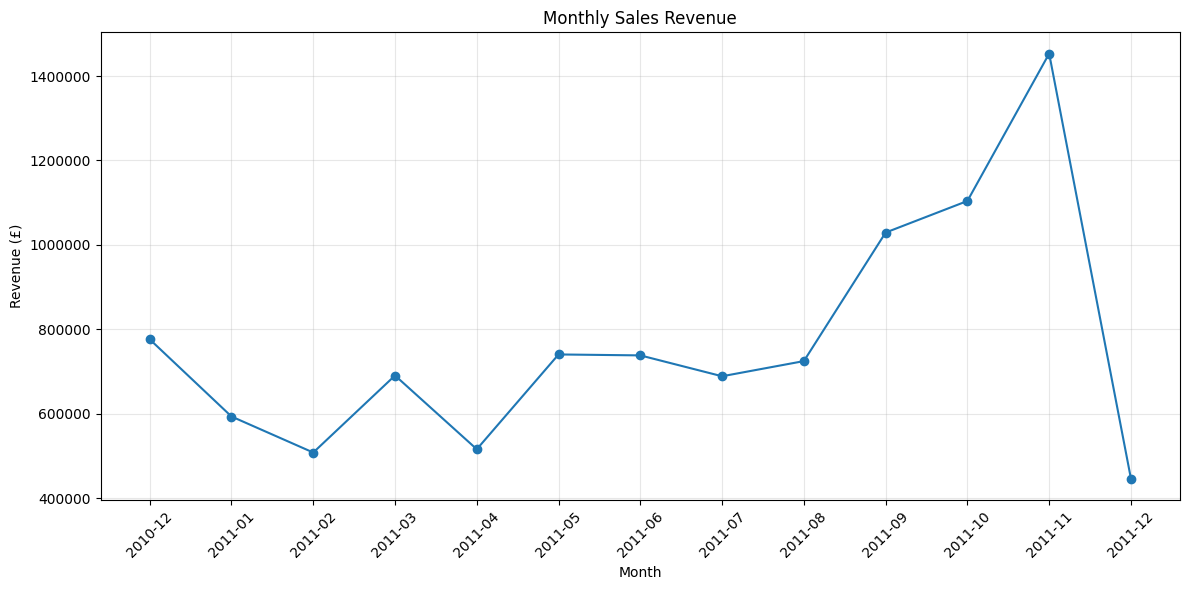

In [36]:
# Plot monthly sales revenue

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"].astype(str),
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

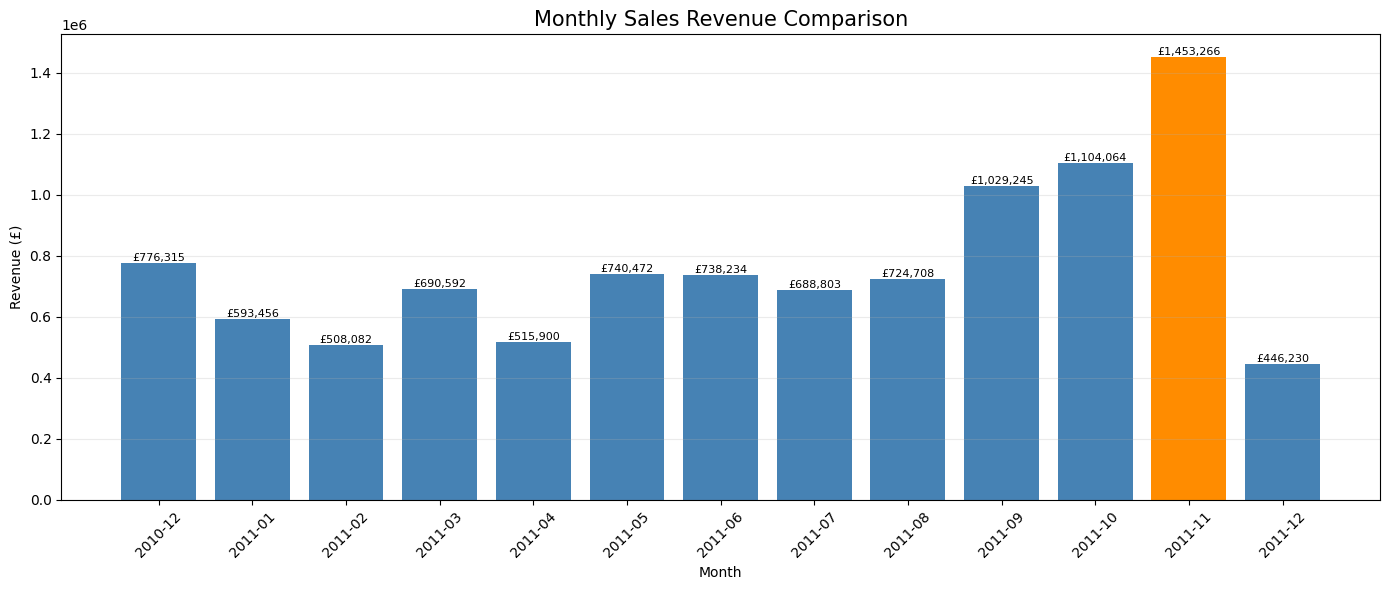

In [37]:
# Compare monthly sales revenue

plt.figure(figsize=(14, 6))

colors = [
    "steelblue" if revenue != monthly_sales["Revenue"].max()
    else "darkorange"
    for revenue in monthly_sales["Revenue"]
]

bars = plt.bar(
    monthly_sales["Month"].astype(str),
    monthly_sales["Revenue"],
    color=colors
)

plt.title("Monthly Sales Revenue Comparison", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

# Add revenue labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"£{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [38]:
# Exclude December 2011 because it contains incomplete monthly data
complete_months = monthly_sales[
    monthly_sales["Month"] != "2011-12"
].copy()

# Sort monthly revenue from highest to lowest
ranked_months = complete_months.sort_values(
    by="Revenue",
    ascending=False
)

print("Top 3 months by revenue:")
display(ranked_months.head(3))

print("Bottom 3 months by revenue:")
display(ranked_months.tail(3).sort_values("Revenue"))

Top 3 months by revenue:


,Month,Revenue
11,2011-11,1453265.980
10,2011-10,1104063.970
9,2011-09,1029245.381


Bottom 3 months by revenue:


,Month,Revenue
2,2011-02,508081.540
4,2011-04,515899.661
1,2011-01,593455.860


### Monthly Sales Performance

Monthly revenue varied throughout the reporting period. November 2011 recorded the highest revenue at £1,453,265.98, followed by October and September. February 2011 had the lowest revenue among the complete months, at £508,081.54.

A noticeable increase in revenue occurred between August and November 2011. This suggests stronger sales activity towards the end of the year. However, further analysis is needed to understand which products, customers or countries contributed to this increase.

December 2011 recorded £446,229.65, but the dataset only covers transactions up to 9 December. Therefore, it has been excluded from comparisons of complete monthly performance.

In [39]:
# Calculate total revenue generated by each product

product_sales = (
    sales_clean.groupby("Description")["LineValue"]
    .sum()
    .reset_index()
)

# Sort products by revenue
product_sales = product_sales.sort_values(
    by="LineValue",
    ascending=False
)

# Display the 10 highest-revenue products
top_10_products = product_sales.head(10)

display(top_10_products)

,Description,LineValue
2846,REGENCY CAKESTAND 3 TIER,174156.54
3837,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
2407,PARTY BUNTING,99445.23
1812,JUMBO BAG RED RETROSPOT,94159.81
2734,RABBIT NIGHT LIGHT,66870.03
2376,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
226,ASSORTED COLOUR BIRD ORNAMENT,58927.62
745,CHILLI LIGHTS,54096.36
3455,SPOTTY BUNTING,42513.48
1810,JUMBO BAG PINK POLKADOT,42401.01


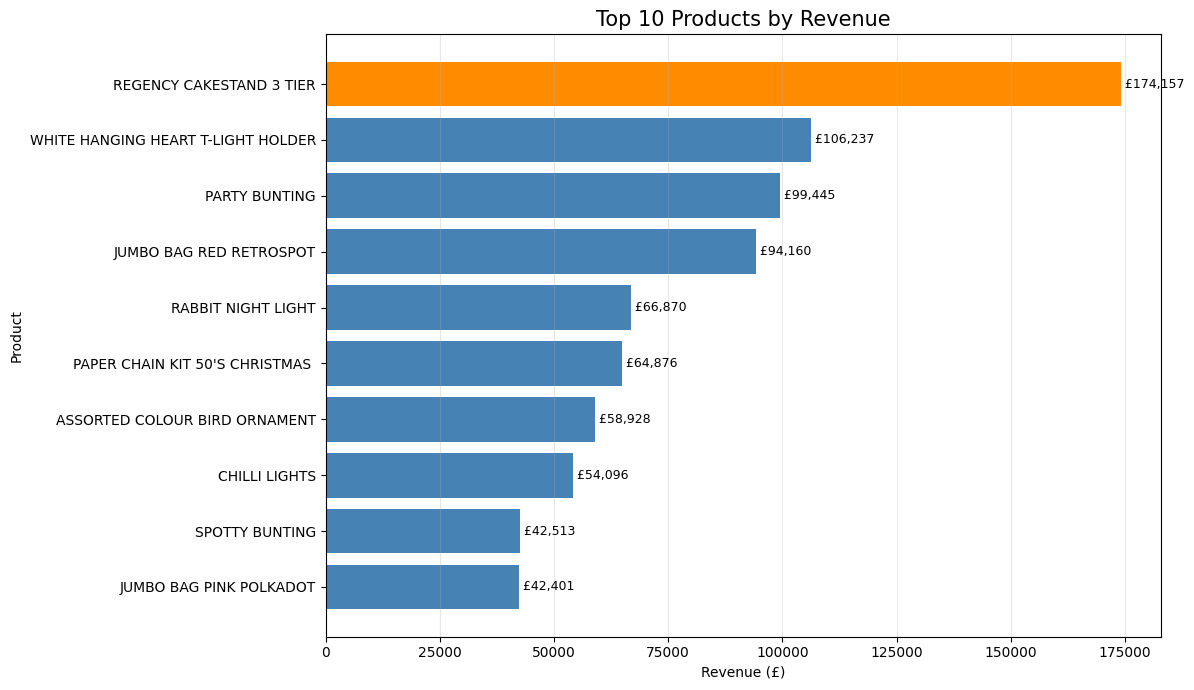

In [40]:
# Prepare the top 10 products for the chart

top_10_products = top_10_products.sort_values(
    by="LineValue",
    ascending=True
)

# Give each product a colour and highlight the top product
colors = [
    "darkorange" if product == "REGENCY CAKESTAND 3 TIER"
    else "steelblue"
    for product in top_10_products["Description"]
]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_products["Description"],
    top_10_products["LineValue"],
    color=colors
)

plt.title("Top 10 Products by Revenue", fontsize=15)
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

# Add revenue labels to the bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" £{width:,.0f}",
        va="center",
        fontsize=9
    )

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Calculate the total quantity sold for each product

product_quantity = (
    sales_clean.groupby("Description")["Quantity"]
    .sum()
    .reset_index()
)

# Rank products by quantity sold
product_quantity = product_quantity.sort_values(
    by="Quantity",
    ascending=False
)

# Display the top 10 products by quantity
top_10_quantity = product_quantity.head(10)

display(top_10_quantity)

,Description,Quantity
3927,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
1812,JUMBO BAG RED RETROSPOT,48371
3837,WHITE HANGING HEART T-LIGHT HOLDER,37872
2675,POPCORN HOLDER,36749
2332,PACK OF 72 RETROSPOT CAKE CASES,36396
226,ASSORTED COLOUR BIRD ORNAMENT,36362
2734,RABBIT NIGHT LIGHT,30739
2103,MINI PAINT SET VINTAGE,26633
2298,PACK OF 12 LONDON TISSUES,26119
2330,PACK OF 60 PINK PAISLEY CAKE CASES,24820


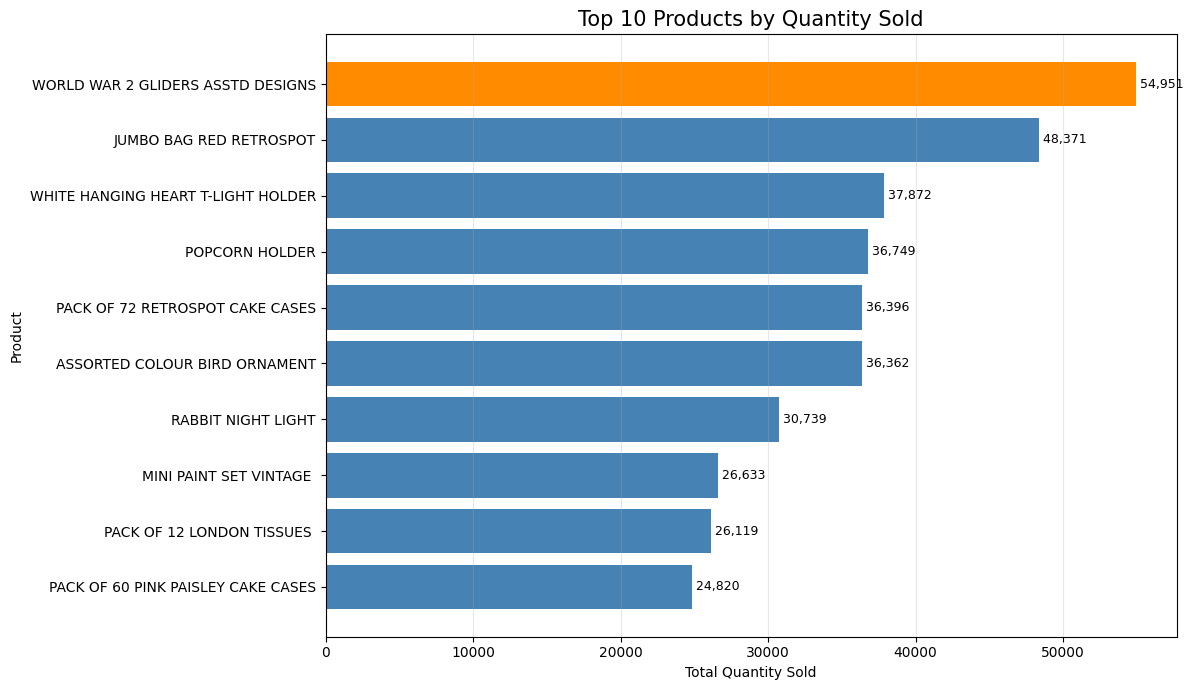

In [42]:
# Arrange products from lowest to highest quantity for the chart

top_10_quantity = top_10_quantity.sort_values(
    by="Quantity",
    ascending=True
)

# Highlight the product with the highest quantity sold
colors = [
    "darkorange" if quantity == top_10_quantity["Quantity"].max()
    else "steelblue"
    for quantity in top_10_quantity["Quantity"]
]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_quantity["Description"],
    top_10_quantity["Quantity"],
    color=colors
)

plt.title("Top 10 Products by Quantity Sold", fontsize=15)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

# Display the quantity at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.0f}",
        va="center",
        fontsize=9
    )

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Combine product revenue and quantity sold

product_performance = sales_clean.groupby("Description").agg(
    Total_Revenue=("LineValue", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate the average selling price for each product
product_performance["Average_Price"] = (
    product_performance["Total_Revenue"] /
    product_performance["Total_Quantity"]
)

# Display the 10 products with the highest revenue
top_product_performance = product_performance.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

display(top_product_performance)

,Description,Total_Revenue,Total_Quantity,Average_Price
2846,REGENCY CAKESTAND 3 TIER,174156.54,13851,12.573572
3837,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2.805152
2407,PARTY BUNTING,99445.23,18283,5.439218
1812,JUMBO BAG RED RETROSPOT,94159.81,48371,1.946617
2734,RABBIT NIGHT LIGHT,66870.03,30739,2.175413
2376,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,3.356386
226,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1.620582
745,CHILLI LIGHTS,54096.36,10302,5.251054
3455,SPOTTY BUNTING,42513.48,8320,5.109793
1810,JUMBO BAG PINK POLKADOT,42401.01,21448,1.976921


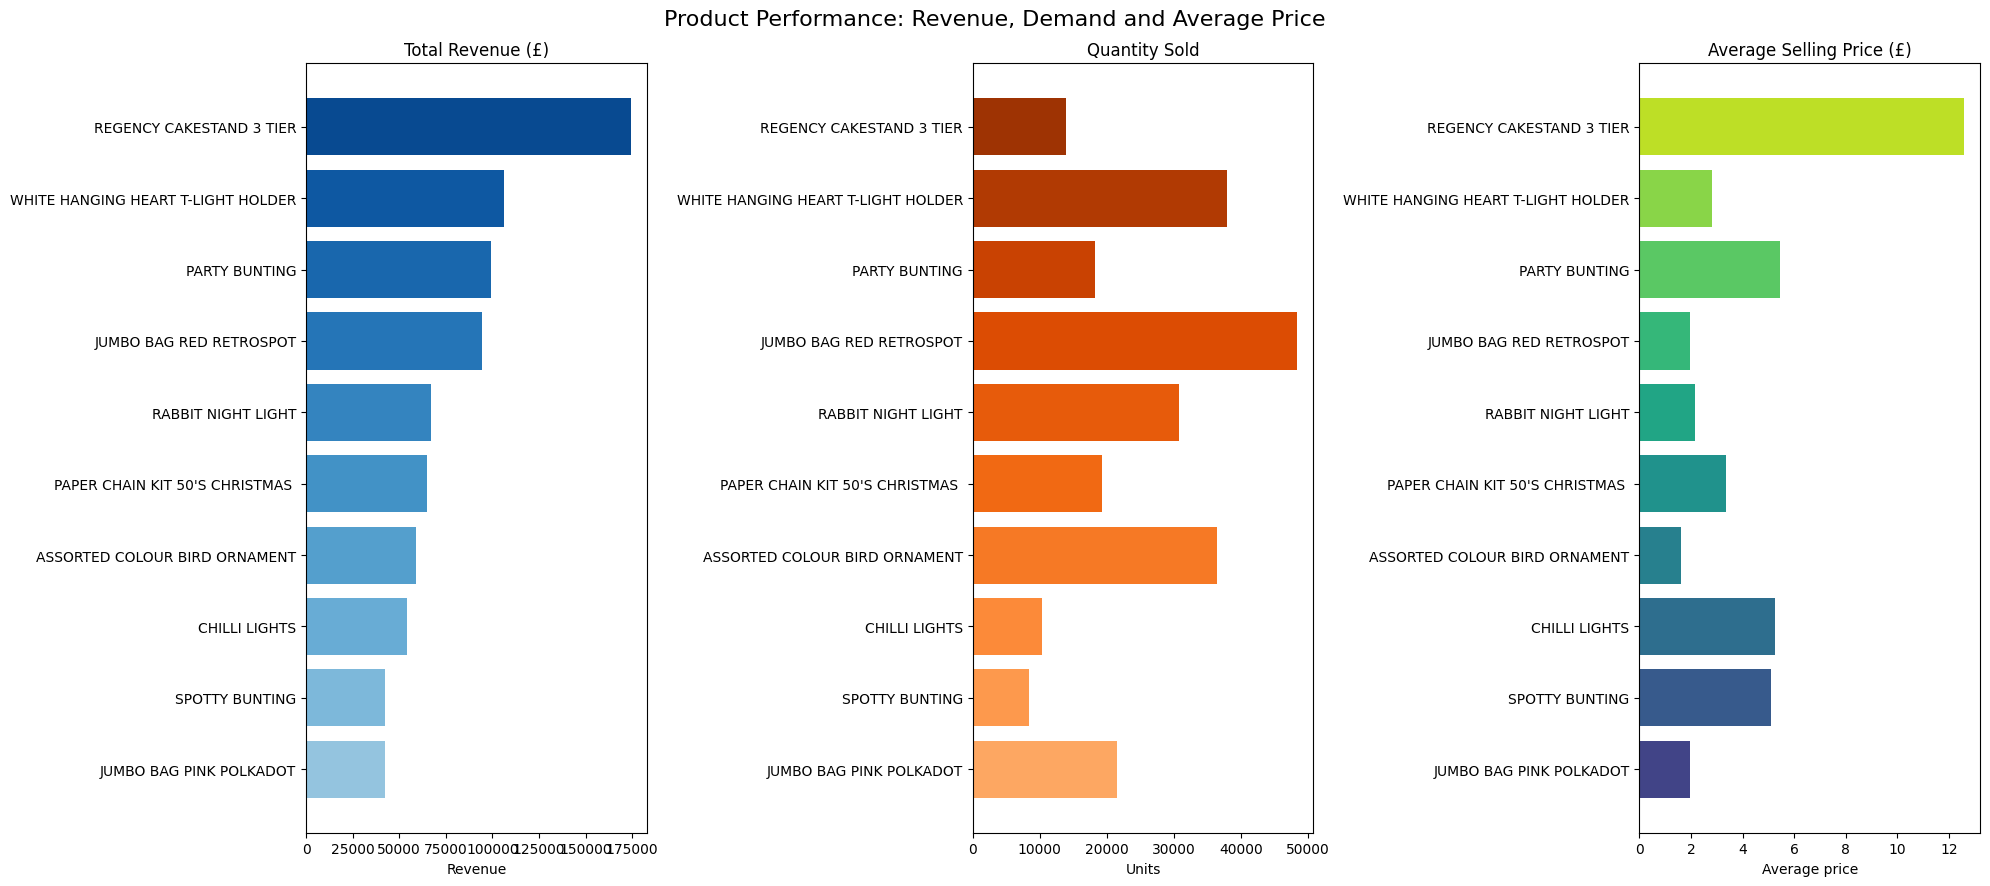

In [44]:
# Compare revenue, quantity sold and average price

fig, axes = plt.subplots(1, 3, figsize=(20, 9))

# Sort products by revenue for consistent ordering
chart_data = top_product_performance.sort_values(
    "Total_Revenue",
    ascending=True
)

# Revenue chart
axes[0].barh(
    chart_data["Description"],
    chart_data["Total_Revenue"],
    color=plt.cm.Blues(np.linspace(0.4, 0.9, len(chart_data)))
)
axes[0].set_title("Total Revenue (£)")
axes[0].set_xlabel("Revenue")

# Quantity chart
axes[1].barh(
    chart_data["Description"],
    chart_data["Total_Quantity"],
    color=plt.cm.Oranges(np.linspace(0.4, 0.9, len(chart_data)))
)
axes[1].set_title("Quantity Sold")
axes[1].set_xlabel("Units")

# Average price chart
axes[2].barh(
    chart_data["Description"],
    chart_data["Average_Price"],
    color=plt.cm.viridis(np.linspace(0.2, 0.9, len(chart_data)))
)
axes[2].set_title("Average Selling Price (£)")
axes[2].set_xlabel("Average price")

fig.suptitle(
    "Product Performance: Revenue, Demand and Average Price",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Product Performance Analysis

The product analysis shows that the products generating the highest revenue are not necessarily those selling the highest number of units.

REGENCY CAKESTAND 3 TIER generated the highest revenue at £174,156.54, with 13,851 units sold and an average selling price of approximately £12.57.

WORLD WAR 2 GLIDERS ASSTD DESIGNS recorded the highest quantity sold, with 54,951 units, although it did not appear among the top 10 products by revenue.

JUMBO BAG RED RETROSPOT performed strongly in both measures, generating £94,159.81 from 48,371 units sold. WHITE HANGING HEART T-LIGHT HOLDER also appeared among the leading products by both revenue and quantity.

These findings show that product performance depends on both sales volume and selling price. The retailer should therefore consider both measures when making decisions about product availability, pricing and stock management.

In [45]:
# Calculate sales performance by country

country_sales = sales_clean.groupby("Country").agg(
    Total_Revenue=("LineValue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Transactions=("InvoiceNo", "nunique")
).reset_index()

# Rank countries by total revenue
country_sales = country_sales.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display the top 10 countries
top_10_countries = country_sales.head(10)

display(top_10_countries)

,Country,Total_Revenue,Total_Quantity,Number_of_Transactions
36,United Kingdom,8481014.333,4483969,17901
24,Netherlands,283889.340,200258,93
10,EIRE,276090.860,147002,284
14,Germany,205381.150,118032,443
13,France,184679.000,111229,383
0,Australia,138103.810,83890,56
31,Spain,55706.560,27724,88
33,Switzerland,53065.600,30515,50
20,Japan,37416.370,26016,19
3,Belgium,36927.340,22962,98


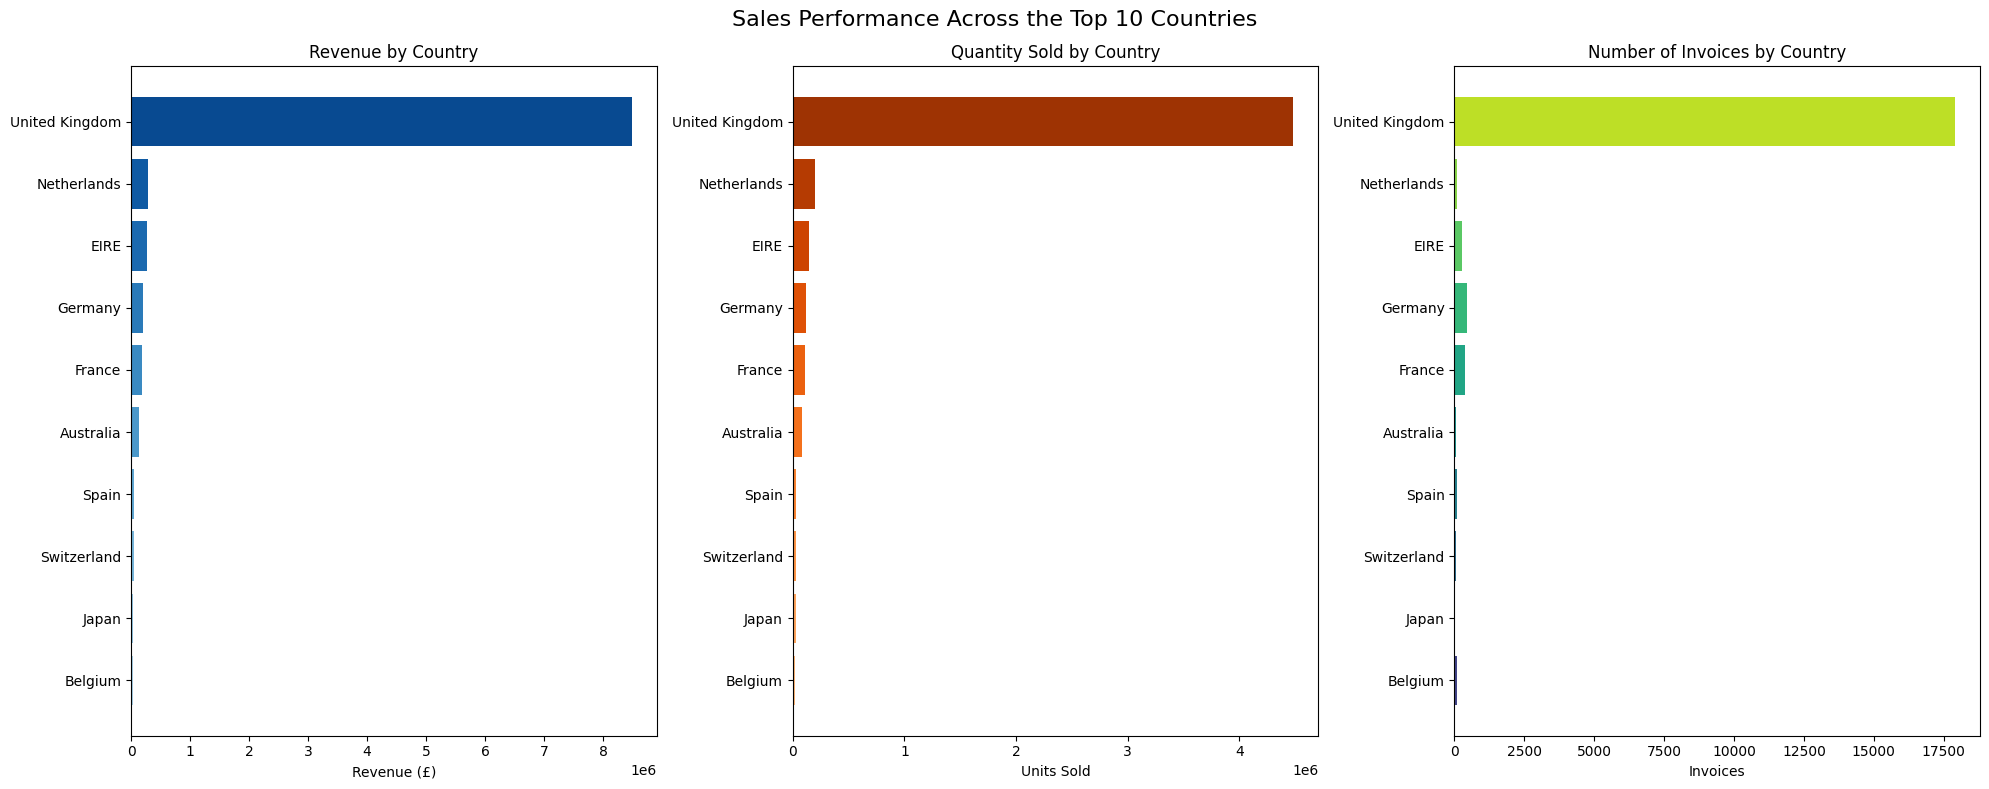

In [46]:
# Prepare the top 10 countries for visualisation

country_chart = top_10_countries.sort_values(
    by="Total_Revenue",
    ascending=True
)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Revenue by country
axes[0].barh(
    country_chart["Country"],
    country_chart["Total_Revenue"],
    color=plt.cm.Blues(np.linspace(0.35, 0.9, len(country_chart)))
)
axes[0].set_title("Revenue by Country")
axes[0].set_xlabel("Revenue (£)")

# Quantity sold by country
axes[1].barh(
    country_chart["Country"],
    country_chart["Total_Quantity"],
    color=plt.cm.Oranges(np.linspace(0.35, 0.9, len(country_chart)))
)
axes[1].set_title("Quantity Sold by Country")
axes[1].set_xlabel("Units Sold")

# Number of invoices by country
axes[2].barh(
    country_chart["Country"],
    country_chart["Number_of_Transactions"],
    color=plt.cm.viridis(np.linspace(0.2, 0.9, len(country_chart)))
)
axes[2].set_title("Number of Invoices by Country")
axes[2].set_xlabel("Invoices")

fig.suptitle(
    "Sales Performance Across the Top 10 Countries",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Country Sales Performance

The country-level analysis shows that the United Kingdom is the retailer's largest market by a considerable margin. It recorded £8,481,014.33 in revenue, with 4,483,969 units sold across 17,901 invoices.

The Netherlands ranked second, generating £283,889.34, followed by EIRE with £276,090.86. Germany and France also featured among the leading markets.

The charts show that the United Kingdom leads not only in revenue but also in quantity sold and number of invoices. This indicates that most of the retailer's recorded sales activity is concentrated in the UK.

Although other European countries and Australia contribute to sales, their revenue figures are considerably lower than those of the UK. This suggests opportunities to investigate international markets and understand what may be limiting their contribution.

Overall, the retailer has a strong domestic market, but its dependence on UK sales is an important factor to consider when evaluating its geographical sales distribution.

In [47]:
# Calculate total revenue across all countries
total_revenue = country_sales["Total_Revenue"].sum()

# Calculate the percentage of total revenue contributed by each country
country_sales["Revenue_Share"] = (
    country_sales["Total_Revenue"] / total_revenue
) * 100

# Display the 10 highest-revenue countries and their revenue shares
top_10_countries = country_sales.head(10).copy()

display(
    top_10_countries[
        ["Country", "Total_Revenue", "Revenue_Share"]
    ].round(2)
)

,Country,Total_Revenue,Revenue_Share
36,United Kingdom,8481014.33,84.73
24,Netherlands,283889.34,2.84
10,EIRE,276090.86,2.76
14,Germany,205381.15,2.05
13,France,184679.00,1.85
0,Australia,138103.81,1.38
31,Spain,55706.56,0.56
33,Switzerland,53065.60,0.53
20,Japan,37416.37,0.37
3,Belgium,36927.34,0.37


### Country Revenue Contribution

The revenue contribution analysis shows that the United Kingdom accounts for 84.73% of the retailer's total revenue, making it by far the largest market.

The Netherlands ranks second with 2.84%, followed by EIRE at 2.76%, Germany at 2.05% and France at 1.85%. Australia contributes 1.38%.

The results show that the retailer depends heavily on its UK market, while international sales account for a relatively small share of overall revenue. The Netherlands, EIRE, Germany and France are among the more significant international markets.

This concentration presents an opportunity to investigate the retailer's international growth potential. However, expanding into other markets would require further investigation of customer demand, delivery costs and market conditions.

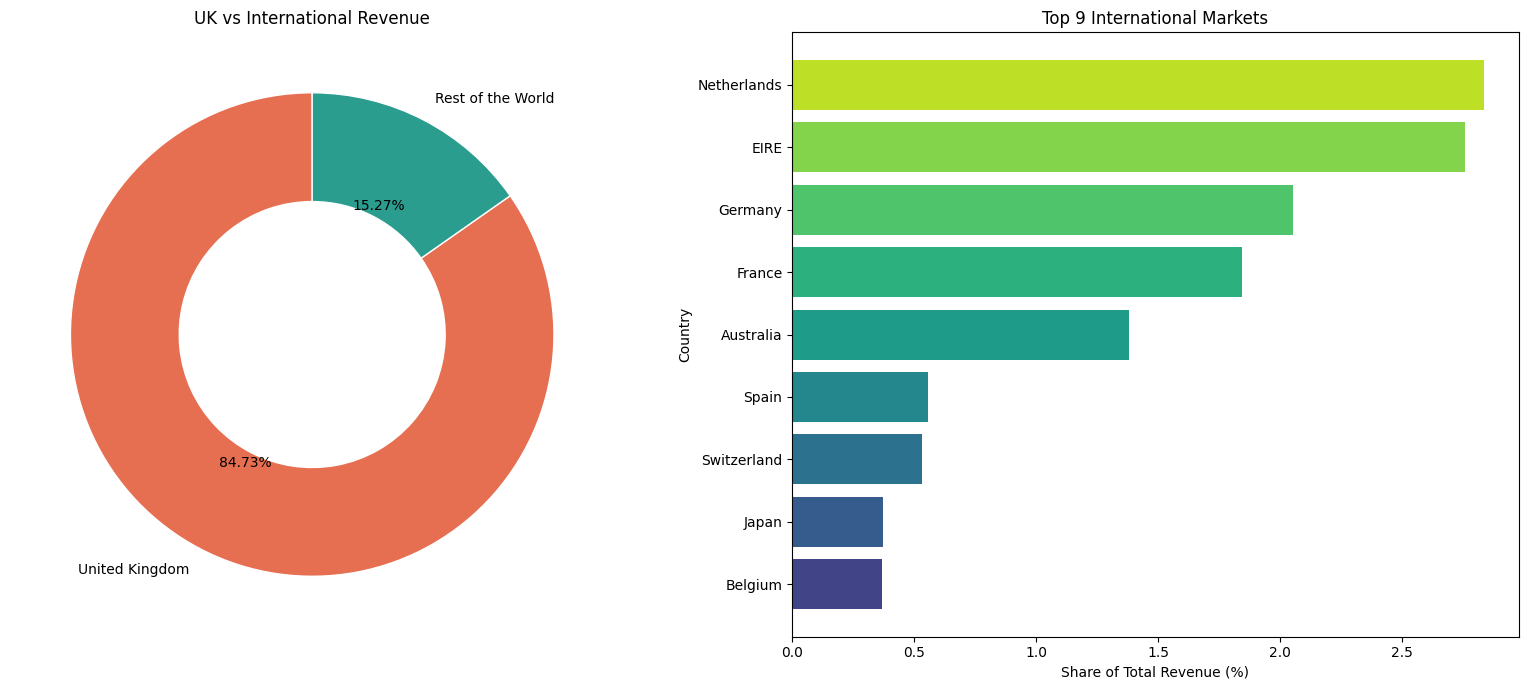

In [48]:
# Calculate revenue from the United Kingdom and all other countries
uk_revenue = country_sales.loc[
    country_sales["Country"] == "United Kingdom",
    "Total_Revenue"
].sum()

international_revenue = total_revenue - uk_revenue

# Prepare the figures for the UK versus international markets chart
market_labels = ["United Kingdom", "Rest of the World"]
market_values = [uk_revenue, international_revenue]

# Create two charts to examine geographical revenue contribution
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Display the UK's share of total revenue using a donut chart
axes[0].pie(
    market_values,
    labels=market_labels,
    autopct="%1.2f%%",
    startangle=90,
    colors=["#E76F51", "#2A9D8F"],
    wedgeprops={"width": 0.45, "edgecolor": "white"}
)

axes[0].set_title("UK vs International Revenue")

# Select the top 9 international markets, excluding the UK
international_countries = country_sales[
    country_sales["Country"] != "United Kingdom"
].head(9).sort_values("Revenue_Share")

# Display the revenue contribution of each international market
axes[1].barh(
    international_countries["Country"],
    international_countries["Revenue_Share"],
    color=plt.cm.viridis(
        np.linspace(0.2, 0.9, len(international_countries))
    )
)

axes[1].set_title("Top 9 International Markets")
axes[1].set_xlabel("Share of Total Revenue (%)")
axes[1].set_ylabel("Country")

plt.tight_layout()
plt.show()

### Visualising Geographical Revenue Contribution

The donut chart highlights the difference between the United Kingdom and international markets. The UK generates 84.73% of total revenue, while all other countries combined contribute 15.27%.

The second chart compares the leading international markets. The Netherlands, EIRE, Germany and France have the highest revenue contributions among these markets.

These visualisations reinforce the finding that the retailer relies heavily on its domestic market. They also help identify international markets that could be investigated further for potential growth.

The charts show revenue distribution, but they do not explain why some countries generate more sales than others. Factors such as customer numbers, order frequency, product preferences and delivery costs would need further investigation.

In [49]:
# Exclude records without a CustomerID for customer-level analysis
customer_data = sales_clean.dropna(subset=["CustomerID"]).copy()

# Group transaction records by customer and calculate purchasing measures
customer_sales = customer_data.groupby("CustomerID").agg(
    Total_Revenue=("LineValue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Orders=("InvoiceNo", "nunique")
).reset_index()

# Calculate the average revenue generated per invoice for each customer
customer_sales["Average_Order_Value"] = (
    customer_sales["Total_Revenue"] / customer_sales["Number_of_Orders"]
)

# Sort customers by total revenue, from highest to lowest
customer_sales = customer_sales.sort_values(
    "Total_Revenue",
    ascending=False
)

# Display the 10 highest-revenue customers
display(customer_sales.head(10).round(2))

,CustomerID,Total_Revenue,Total_Quantity,Number_of_Orders,Average_Order_Value
1688,14646.0,279138.02,196844,72,3876.92
4196,18102.0,259657.30,64124,60,4327.62
3724,17450.0,194390.79,69973,46,4225.89
1878,14911.0,140336.83,80238,199,705.21
54,12415.0,124564.53,77373,20,6228.23
1332,14156.0,117210.08,57768,55,2131.09
3767,17511.0,91062.38,64549,31,2937.50
2699,16029.0,72708.09,40107,62,1172.71
3173,16684.0,66653.56,50255,28,2380.48
995,13694.0,65039.62,63312,50,1300.79


- Customer 14646 generated the highest revenue, approximately £279,138.02, from 72 distinct invoices.
- Customer 18102 ranked second, generating approximately £259,657.30 from 60 invoices.
- Customer 17450 ranked third, generating approximately £194,390.79 from 46 invoices.
- Customer 14911 had 199 invoices, the highest order count among the ten customers shown, but generated less revenue than the top three.
This shows that the highest-revenue customers are not necessarily those who place the most orders. Both spending per order and purchasing frequency contribute to total customer revenue.

In [50]:
# Calculate the overall customer purchasing statistics
total_customers = customer_sales["CustomerID"].nunique()

total_customer_revenue = customer_sales["Total_Revenue"].sum()

total_customer_orders = customer_sales["Number_of_Orders"].sum()

average_revenue_per_customer = (
    total_customer_revenue / total_customers
)

# Display the summary of customer activity
customer_summary = pd.DataFrame({
    "Metric": [
        "Number of Identified Customers",
        "Total Customer Revenue",
        "Total Customer Orders",
        "Average Revenue per Customer"
    ],
    "Value": [
        total_customers,
        total_customer_revenue,
        total_customer_orders,
        average_revenue_per_customer
    ]
})

display(customer_summary.round(2))

,Metric,Value
0,Number of Identified Customers,4333.00
1,Total Customer Revenue,8498260.44
2,Total Customer Orders,18403.00
3,Average Revenue per Customer,1961.29


- The analysis identified 4,333 customers with recorded customer IDs.
- These customers generated approximately £8.50 million in revenue.
- The average customer generated approximately £1,961.29 over the dataset period.
- The 18,403 orders represent distinct invoices counted within each customer's records.
One useful comparison: Total identified-customer revenue is lower than overall sales revenue because transactions without a CustomerID are excluded from customer-level analysis. This is intentional.

In [52]:
# Examine the range and distribution of customer revenue
display(
    customer_sales["Total_Revenue"].describe().round(2)
)

,Total_Revenue
count,4333.00
mean,1961.29
std,8478.73
min,2.90
25%,304.25
50%,661.52
75%,1628.56
max,279138.02


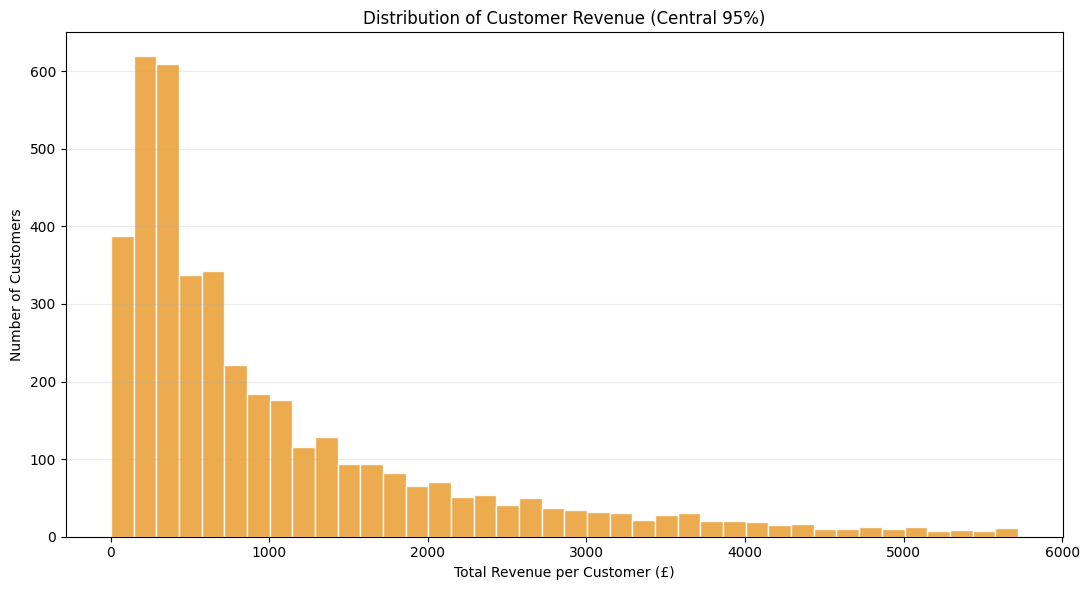

In [53]:
# Calculate the 95th percentile of customer revenue
revenue_limit = customer_sales["Total_Revenue"].quantile(0.95)

# Select customers within the central 95% of the revenue distribution
typical_customer_revenue = customer_sales.loc[
    customer_sales["Total_Revenue"] <= revenue_limit,
    "Total_Revenue"
]

# Plot the distribution without allowing extreme values to dominate the scale
plt.figure(figsize=(11, 6))

plt.hist(
    typical_customer_revenue,
    bins=40,
    color="#E9A23B",
    edgecolor="white",
    alpha=0.9
)

plt.title("Distribution of Customer Revenue (Central 95%)")
plt.xlabel("Total Revenue per Customer (£)")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Customer Revenue Distribution

The customer revenue analysis shows that spending varies considerably across the retailer's customer base.

The median customer generated £661.52 in revenue, while the average was £1,961.29. The difference between these figures suggests that a relatively small number of high-spending customers raise the overall average.

The highest-spending customer generated £279,138.02, compared with £2.90 for the lowest-spending customer.

The histogram displays the central 95% of customers to make the typical spending pattern easier to examine. The highest 5% were excluded from this visualisation only; they remain included in the underlying dataset and calculations.

Overall, the results suggest that customer spending is concentrated among a smaller group of high-value customers. This makes it useful to examine customer purchasing frequency and identify customers who contribute most to revenue.

,Number_of_Customers
Number_of_Orders,
1 order,1505
2–5 orders,1963
6–10 orders,533
11–20 orders,238
More than 20 orders,94


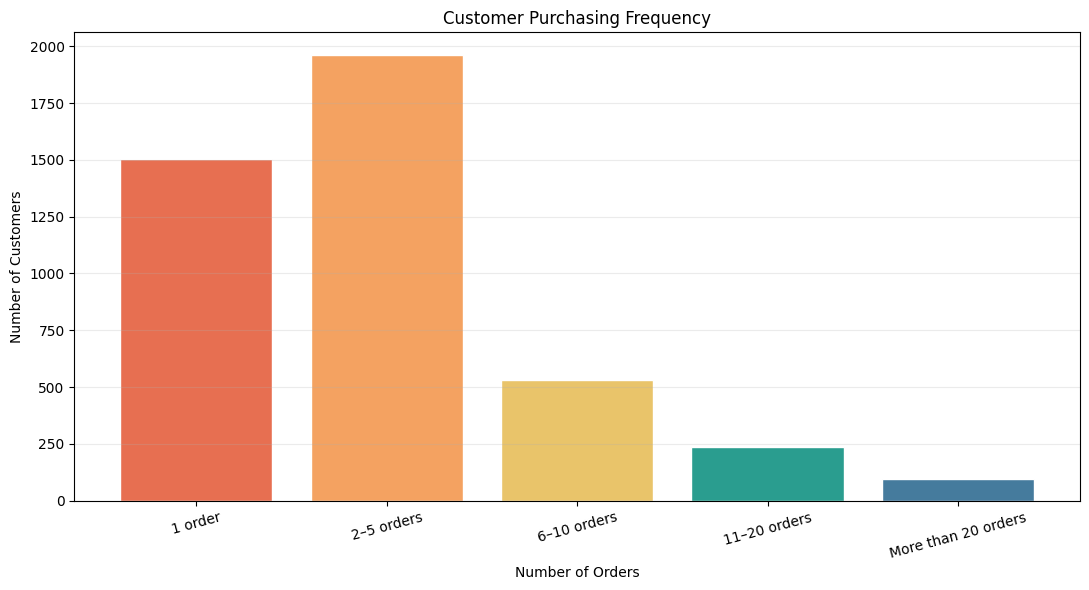

In [54]:
# Count how many customers fall into each order-frequency group
order_frequency = customer_sales["Number_of_Orders"].value_counts().sort_index()

# Group customers into practical purchasing-frequency categories
frequency_groups = pd.cut(
    customer_sales["Number_of_Orders"],
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=[
        "1 order",
        "2–5 orders",
        "6–10 orders",
        "11–20 orders",
        "More than 20 orders"
    ]
)

# Calculate the number of customers in each frequency category
frequency_summary = frequency_groups.value_counts().sort_index()

# Display the customer purchasing-frequency summary
display(
    frequency_summary.rename("Number_of_Customers").to_frame()
)

# Plot the distribution of customers across frequency categories
plt.figure(figsize=(11, 6))

plt.bar(
    frequency_summary.index.astype(str),
    frequency_summary.values,
    color=["#E76F51", "#F4A261", "#E9C46A", "#2A9D8F", "#457B9D"],
    edgecolor="white"
)

plt.title("Customer Purchasing Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Customer Purchasing Frequency

The purchasing-frequency analysis shows differences in how often customers bought from the retailer during the dataset period.

The largest group consisted of customers who placed between 2 and 5 orders, representing 45.3% of identified customers. A further 34.7% placed only one order.

Approximately 65.3% of customers made more than one purchase, while only 7.7% placed more than 10 orders.

These findings suggest that the retailer has a substantial base of occasional customers alongside a smaller group of frequent buyers. Encouraging one-time buyers to make repeat purchases and retaining frequent customers could be useful areas for further business investigation.

The analysis covers the available dataset period and does not establish whether customers continued purchasing after the dataset ended.

,Frequency_Group,Number_of_Customers,Average_Revenue,Median_Revenue
0,1 order,1505,365.48,255.90
1,2–5 orders,1963,1103.66,778.94
2,6–10 orders,533,2789.20,2314.32
3,11–20 orders,238,6966.52,4751.42
4,More than 20 orders,94,28053.68,11637.84


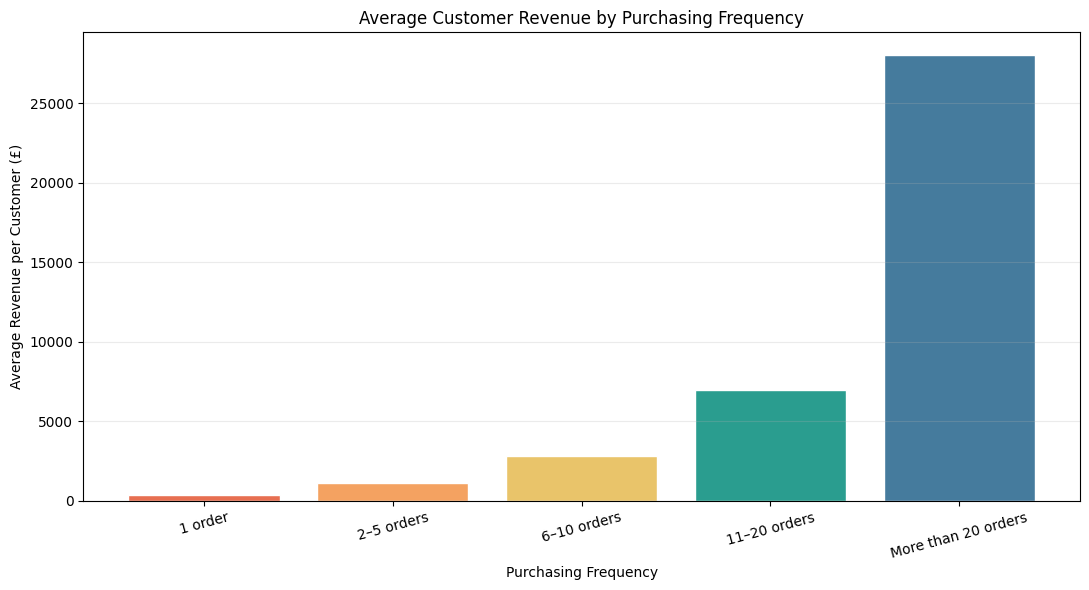

In [55]:
# Assign each customer to a purchasing-frequency category
customer_sales["Frequency_Group"] = pd.cut(
    customer_sales["Number_of_Orders"],
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=[
        "1 order",
        "2–5 orders",
        "6–10 orders",
        "11–20 orders",
        "More than 20 orders"
    ]
)

# Calculate average customer revenue and customer count in each group
frequency_revenue = customer_sales.groupby(
    "Frequency_Group",
    observed=False
).agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Revenue=("Total_Revenue", "mean"),
    Median_Revenue=("Total_Revenue", "median")
).reset_index()

# Display the revenue comparison
display(frequency_revenue.round(2))

# Compare average customer revenue across purchasing-frequency groups
plt.figure(figsize=(11, 6))

plt.bar(
    frequency_revenue["Frequency_Group"].astype(str),
    frequency_revenue["Average_Revenue"],
    color=["#E76F51", "#F4A261", "#E9C46A", "#2A9D8F", "#457B9D"],
    edgecolor="white"
)

plt.title("Average Customer Revenue by Purchasing Frequency")
plt.xlabel("Purchasing Frequency")
plt.ylabel("Average Revenue per Customer (£)")
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Customer Revenue by Purchasing Frequency

The analysis shows a clear positive relationship between purchasing frequency and average customer revenue.

Customers who placed only one order generated an average of £365.48, while those who placed between 2 and 5 orders generated £1,103.66.

Average revenue increased across the remaining groups, reaching £6,966.52 for customers who placed 11–20 orders. Customers with more than 20 orders generated the highest average revenue at £28,053.68.

The median revenue was lower than the average in every group, indicating that a number of high-spending customers influence the average figures.

These findings suggest that frequent customers are an important source of revenue. The retailer could investigate ways to encourage repeat purchases while maintaining relationships with its existing high-value customers.

The results show an association between purchasing frequency and revenue, rather than proving that more orders directly cause higher customer spending.

In [56]:
# Set the reference date to one day after the latest recorded transaction
reference_date = sales_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate recency, frequency and monetary value for each identified customer
rfm = customer_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineValue", "sum")
).reset_index()

# Sort customers by monetary value, from highest to lowest
rfm = rfm.sort_values("Monetary", ascending=False)

# Display the first 10 customers in the RFM dataset
display(rfm.head(10).round(2))

,CustomerID,Recency,Frequency,Monetary
1688,14646.0,2,72,279138.02
4196,18102.0,1,60,259657.30
3724,17450.0,8,46,194390.79
1878,14911.0,1,199,140336.83
54,12415.0,24,20,124564.53
1332,14156.0,10,55,117210.08
3767,17511.0,3,31,91062.38
2699,16029.0,39,62,72708.09
3173,16684.0,4,28,66653.56
995,13694.0,4,50,65039.62


In [57]:
# Display the reference date used for the RFM calculations
print("RFM reference date:", reference_date)

# Check the range and distribution of the three RFM measures
display(
    rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)
)

# Check for missing or invalid RFM values
print("\nMissing values:")
display(rfm[["Recency", "Frequency", "Monetary"]].isna().sum())

print("\nNon-positive values:")
display((rfm[["Recency", "Frequency", "Monetary"]] <= 0).sum())

RFM reference date: 2011-12-10 12:50:00


,Recency,Frequency,Monetary
count,4333.00,4333.00,4333.00
mean,92.70,4.25,1961.29
std,100.13,7.64,8478.73
min,1.00,1.00,2.90
25%,18.00,1.00,304.25
50%,51.00,2.00,661.52
75%,143.00,5.00,1628.56
max,374.00,206.00,279138.02



Missing values:


,0
Recency,0
Frequency,0
Monetary,0



Non-positive values:


,0
Recency,0
Frequency,0
Monetary,0


In [58]:
# Define the percentile boundaries used to divide customers into five score groups
score_bins = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Calculate percentile ranks, giving tied values the same average rank
recency_rank = rfm["Recency"].rank(method="average", pct=True)
frequency_rank = rfm["Frequency"].rank(method="average", pct=True)
monetary_rank = rfm["Monetary"].rank(method="average", pct=True)

# Assign recency scores in reverse order because fewer days indicate better recency
rfm["R_Score"] = pd.cut(
    recency_rank,
    bins=score_bins,
    labels=[5, 4, 3, 2, 1],
    include_lowest=True
).astype(int)

# Assign higher scores to customers with greater purchasing frequency
rfm["F_Score"] = pd.cut(
    frequency_rank,
    bins=score_bins,
    labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

# Assign higher scores to customers with greater monetary value
rfm["M_Score"] = pd.cut(
    monetary_rank,
    bins=score_bins,
    labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

# Combine the three individual scores into one RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Display the scored customer records
display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
1688,14646.0,2,72,279138.02,5,5,5,555
4196,18102.0,1,60,259657.30,5,5,5,555
3724,17450.0,8,46,194390.79,5,5,5,555
1878,14911.0,1,199,140336.83,5,5,5,555
54,12415.0,24,20,124564.53,4,5,5,455
1332,14156.0,10,55,117210.08,5,5,5,555
3767,17511.0,3,31,91062.38,5,5,5,555
2699,16029.0,39,62,72708.09,3,5,5,355
3173,16684.0,4,28,66653.56,5,5,5,555
995,13694.0,4,50,65039.62,5,5,5,555


In [59]:
# Check that all customers received a score for each RFM measure
print("Missing RFM scores:")
display(rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]].isna().sum())

# Display the minimum and maximum individual scores
print("\nScore ranges:")
display(rfm[["R_Score", "F_Score", "M_Score"]].agg(["min", "max"]))

# Count customers receiving each individual score
print("\nIndividual score distributions:")
for column in ["R_Score", "F_Score", "M_Score"]:
    display(rfm[column].value_counts().sort_index().rename(column))

# Display the most common combined RFM scores
print("\nMost common combined RFM scores:")
display(rfm["RFM_Score"].value_counts().head(10))

Missing RFM scores:


,0
R_Score,0
F_Score,0
M_Score,0
RFM_Score,0



Score ranges:


,R_Score,F_Score,M_Score
min,1,1,1
max,5,5,5



Individual score distributions:


,R_Score
R_Score,
1,867
2,868
3,871
4,863
5,864


,F_Score
F_Score,
1,1505
3,1332
4,631
5,865


,M_Score
M_Score,
1,866
2,867
3,866
4,867
5,867



Most common combined RFM scores:


,count
RFM_Score,
555,348
111,330
112,209
455,173
211,147
233,139
311,132
333,117
212,109


In [60]:
# Confirm that every customer has all four RFM scores
print("Missing scores:")
print(rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]].isna().sum())

# Display the distribution of recency scores
print("\nRecency score distribution:")
print(rfm["R_Score"].value_counts().sort_index())

Missing scores:
R_Score      0
F_Score      0
M_Score      0
RFM_Score    0
dtype: int64

Recency score distribution:
R_Score
1    867
2    868
3    871
4    863
5    864
Name: count, dtype: int64


In [61]:
# Assign frequency scores using the order-frequency bands
rfm["F_Score"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Rebuild the combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Check that all five frequency scores are represented
print("Frequency score distribution:")
print(rfm["F_Score"].value_counts().sort_index())

# Confirm that no scores are missing
print("\nMissing RFM scores:")
print(rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]].isna().sum())

Frequency score distribution:
F_Score
1    1505
2    1963
3     533
4     238
5      94
Name: count, dtype: int64

Missing RFM scores:
R_Score      0
F_Score      0
M_Score      0
RFM_Score    0
dtype: int64


In [62]:
# Define customer segments using RFM score conditions
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),
    (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 3),
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] <= 2),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] <= 2),
]

# Assign a descriptive label to each matching condition
segment_names = [
    "Champions",
    "Loyal Customers",
    "Recent Customers",
    "At Risk",
    "Lost Customers",
]

# Apply the rules and label customers not covered by them
rfm["Customer_Segment"] = np.select(
    conditions,
    segment_names,
    default="Other Customers"
)

# Summarise the number of customers in each segment
segment_summary = (
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Number_of_Customers")
)

# Calculate each segment's share of identified customers
segment_summary["Percentage"] = (
    segment_summary["Number_of_Customers"]
    / len(rfm) * 100
).round(2)

display(segment_summary)

,Customer_Segment,Number_of_Customers,Percentage
0,Lost Customers,1671,38.56
1,Other Customers,1230,28.39
2,Recent Customers,1047,24.16
3,Champions,302,6.97
4,At Risk,53,1.22
5,Loyal Customers,30,0.69


In [63]:
# Join each customer's revenue to their RFM segment
rfm_analysis = rfm.merge(
    customer_sales[["CustomerID", "Total_Revenue"]],
    on="CustomerID",
    how="left"
)

# Summarise customer numbers and revenue by segment
segment_value = (
    rfm_analysis.groupby("Customer_Segment")
    .agg(
        Number_of_Customers=("CustomerID", "count"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue_Per_Customer=("Total_Revenue", "mean")
    )
    .reset_index()
)

# Calculate each segment's contribution to identified-customer revenue
segment_value["Revenue_Share"] = (
    segment_value["Total_Revenue"]
    / segment_value["Total_Revenue"].sum() * 100
).round(2)

# Display the results, highest revenue segment first
display(
    segment_value.sort_values(
        "Total_Revenue",
        ascending=False
    ).round(2)
)

,Customer_Segment,Number_of_Customers,Total_Revenue,Average_Revenue_Per_Customer,Revenue_Share
1,Champions,302,4082399.69,13517.88,48.04
4,Other Customers,1230,1993094.86,1620.40,23.45
2,Lost Customers,1671,1076428.87,644.18,12.67
5,Recent Customers,1047,1004541.08,959.45,11.82
3,Loyal Customers,30,212677.42,7089.25,2.50
0,At Risk,53,129118.52,2436.20,1.52


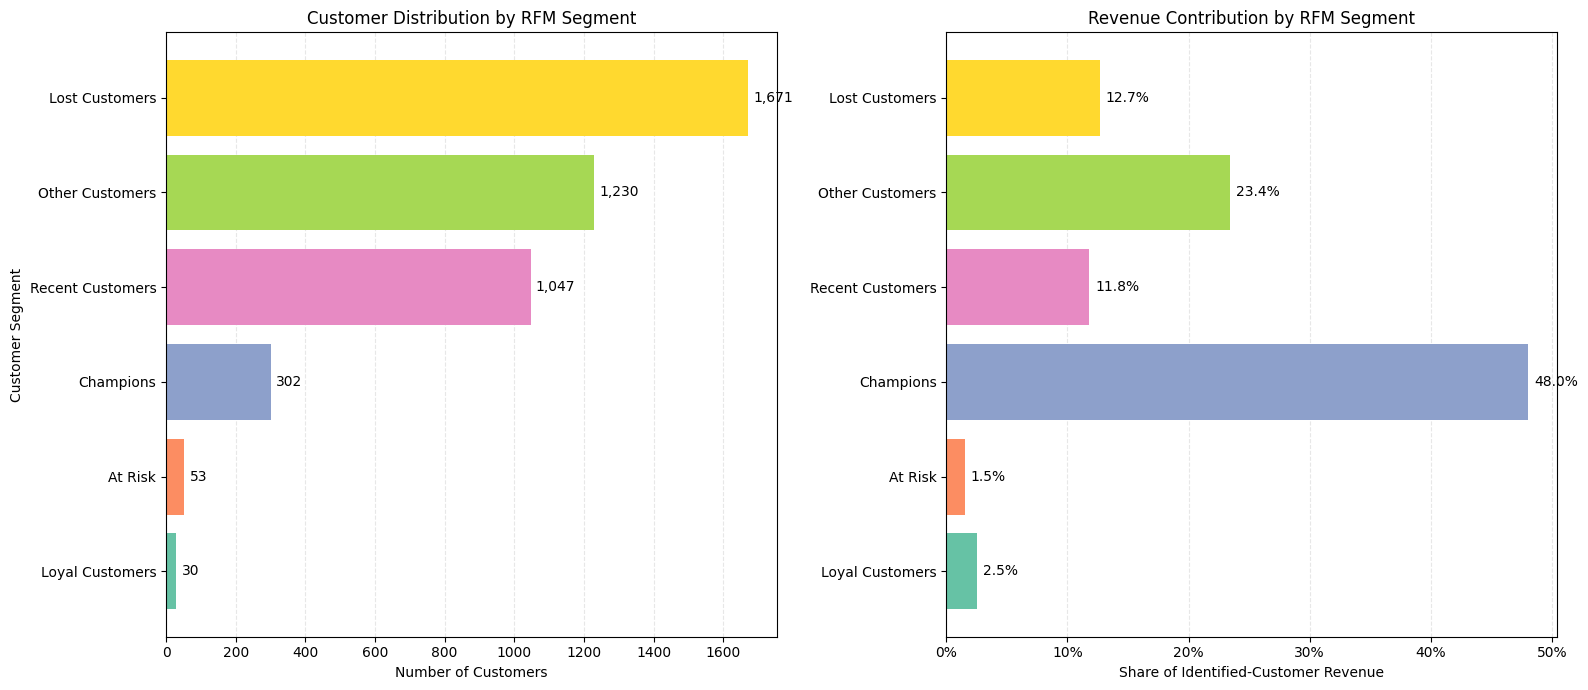

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Sort segments by customer count for consistent chart ordering
plot_data = segment_value.sort_values(
    "Number_of_Customers",
    ascending=True
)

# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Use distinct colours for the six customer segments
palette = sns.color_palette("Set2", n_colors=len(plot_data))

# Chart 1: Number of customers in each segment
axes[0].barh(
    plot_data["Customer_Segment"],
    plot_data["Number_of_Customers"],
    color=palette
)
axes[0].set_title("Customer Distribution by RFM Segment")
axes[0].set_xlabel("Number of Customers")
axes[0].set_ylabel("Customer Segment")

# Chart 2: Revenue contribution by segment
axes[1].barh(
    plot_data["Customer_Segment"],
    plot_data["Revenue_Share"] / 100,
    color=palette
)
axes[1].set_title("Revenue Contribution by RFM Segment")
axes[1].set_xlabel("Share of Identified-Customer Revenue")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))

# Add labels to both charts
for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

for bar in axes[0].patches:
    axes[0].text(
        bar.get_width() + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center"
    )

for bar in axes[1].patches:
    axes[1].text(
        bar.get_width() + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1%}",
        va="center"
    )

plt.tight_layout()
plt.show()

Champions account for 6.97% of identified customers but contribute 48.04% of their revenue, making them a particularly valuable customer group.



Lost Customers form the largest segment at 38.56%, but contribute 12.67% of revenue. This group may offer opportunities for targeted re-engagement.



Recent Customers represent 24.16% of customers and contribute 11.82% of revenue. Their future purchasing behaviour can be monitored to identify customers who develop into repeat buyers.



Loyal Customers are a small group (0.69%) but have a relatively high average revenue per customer (£7,089.25).



The results show that customer numbers and revenue contribution are not proportional. Retention and engagement strategies should therefore consider both customer activity and financial value.

RFM segments are rule-based classifications using the scoring thresholds defined in this project. They describe purchasing patterns in this dataset; they do not establish why customers stopped purchasing or predict future behaviour.

# Overall Findings and Business Recommendations

## 1. Overall Project Findings

### Sales Performance

The analysis recorded total product sales revenue of **£10,009,365.98** after the data cleaning and transaction filtering process. Monthly revenue varied throughout the observation period, with November 2011 recording the highest revenue at approximately **£1.45 million**. February 2011 recorded the lowest monthly revenue, at approximately **£508,081.54**.

Revenue increased considerably between August and November 2011. December 2011 recorded approximately £446,229.65, but the dataset ends on 9 December 2011. It is therefore an incomplete month and should not be compared directly with full months.

### Product Performance

The product analysis showed that the **Regency Cakestand 3 Tier** generated the highest revenue, contributing approximately **£174,156.54**. However, the **World War 2 Gliders Asstd Designs** recorded the highest sales volume, with 54,951 units sold.

This demonstrates that products with the highest sales quantities are not necessarily the products generating the most revenue. Both revenue and sales volume are useful measures when evaluating product performance.

### Geographical Performance

The United Kingdom was the dominant market, contributing approximately **84.73% of total product sales revenue**. The Netherlands, Ireland (EIRE), Germany and France were among the leading international markets.

The concentration of revenue in the UK indicates that the business relies heavily on its domestic market. International markets may provide opportunities for further growth, although differences in customer demand, order sizes and market conditions should be considered.

### Customer Purchasing Behaviour

The customer analysis identified **4,333 customers with available CustomerIDs** in the cleaned product sales data. Their combined revenue was approximately **£8.50 million**.

Purchasing frequency varied considerably. Approximately 34.7% of identified customers placed one order, while 45.3% placed between two and five orders. Only 7.7% placed more than ten orders.

Customer revenue was also unevenly distributed. A relatively small number of customers generated substantially higher revenue than the typical customer, indicating the importance of understanding both purchasing frequency and customer value.

### RFM Analysis

The RFM analysis classified the 4,333 identified customers using recency, frequency and monetary value.

The Champions segment contained **302 customers (6.97%)** and generated approximately **48.04% of identified-customer revenue**. This makes the segment particularly important from a revenue perspective.

Lost Customers formed the largest segment, containing **1,671 customers (38.56%)** and contributing approximately **12.67% of identified-customer revenue**. Recent Customers accounted for 24.16% of customers, while Loyal Customers represented a smaller group of 30 customers.

These results show that customer numbers alone do not reflect financial contribution. Customer activity and spending patterns provide additional information for understanding customer value.

## 2. Business Recommendations

Based on the findings, the following actions could be considered:

1. **Strengthen customer retention:** Maintain engagement with high-value customers, particularly those classified as Champions, through personalised communication, loyalty incentives and reliable customer service.

2. **Re-engage inactive customers:** Investigate the Lost Customers segment and consider targeted campaigns to encourage previous customers to purchase again. The business should test these campaigns rather than assume every inactive customer can be recovered.

3. **Encourage repeat purchases:** Monitor Recent Customers and develop suitable follow-up offers or product recommendations that may encourage a second purchase.

4. **Review product performance:** Maintain the availability of strong revenue-generating products while also monitoring high-volume products. Product decisions should consider revenue, quantity sold and profitability where cost data is available.

5. **Explore international markets:** Assess opportunities in established international markets such as the Netherlands, EIRE, Germany and France. Further analysis of market-specific demand and order patterns would help guide expansion decisions.

6. **Monitor monthly sales trends:** Use regular sales reporting to identify changes in demand and support inventory and promotional planning. Comparisons should account for incomplete reporting periods.

## 3. Data Limitations

The findings should be interpreted in light of several limitations:

- The dataset covers December 2010 to December 2011 and may not reflect current purchasing behaviour.
- Approximately 25% of records in the cleaned dataset had missing CustomerIDs. These records were retained for overall product sales analysis but excluded from customer-specific analysis.
- Cancelled transactions, returns, adjustments and administrative records were separated from ordinary product sales during cleaning.
- December 2011 is incomplete because the available data ends on 9 December.
- The dataset does not provide product costs, so the analysis measures revenue rather than profit.
- RFM segments are based on defined scoring rules and describe historical purchasing patterns. They do not establish customer intentions or predict future behaviour.

## 4. Conclusion

This project demonstrates how data cleaning, exploratory data analysis and customer segmentation can be used to extract useful business insights from transactional retail data.

The analysis identified important sales trends, high-performing products, geographical revenue concentration and differences in customer purchasing behaviour. The RFM analysis further showed that a relatively small group of high-value customers contributed a substantial proportion of identified-customer revenue.

Overall, the findings provide a basis for more informed decisions concerning customer retention, product management, market development and sales monitoring. They also demonstrate the value of using statistical analysis and Python to turn raw transactional data into meaningful business information.